<a href="https://colab.research.google.com/github/saiashritha-gudla/AgriVerse-AI/blob/main/agriverse_ai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q langgraph langchain langchain-groq groq chromadb sentence-transformers requests
print("Packages installed.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 664.1 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60

In [ ]:
import os

drive.mount('/content/gdrive')

PROJECT_DIR = '/content/gdrive/MyDrive/ai_engineer_3_project'

os.makedirs(PROJECT_DIR, exist_ok=True)

print(f"Project files will be saved to: {PROJECT_DIR}")

Mounted at /content/gdrive
Project files will be saved to: /content/gdrive/MyDrive/ai_engineer_3_project


In [ ]:
!pip install -q pyngrok
from pyngrok import ngrok
from google.colab import userdata

ngrok.set_auth_token(userdata.get("NGROK_AUTH_TOKEN"))

In [ ]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="llama-3.3-70b-versatile",
    temperature=0.3,
)

response = llm.invoke("In one sentence, why is soil moisture important for irrigation planning?")
print(response.content)

Soil moisture is important for irrigation planning because it helps determine the optimal amount and timing of water application, ensuring that crops receive the right amount of water to promote healthy growth while minimizing waste and reducing the risk of overwatering or underwatering.


In [ ]:
mport requests

def get_coordinates(location_name: str):
    """Convert a place name to lat/lon using Open-Meteo's free geocoding API."""
    url = "https://geocoding-api.open-meteo.com/v1/search"
    params = {"name": location_name, "count": 1}
    resp = requests.get(url, params=params).json()
    if not resp.get("results"):
        raise ValueError(f"Could not find location: {location_name}")
    result = resp["results"][0]
    return result["latitude"], result["longitude"], result.get("country", "")


def get_weather_data(lat: float, lon: float):
    """Fetch current + 5-day forecast from Open-Meteo."""
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": lat,
        "longitude": lon,
        "current": "temperature_2m,precipitation,wind_speed_10m",
        "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum",
        "forecast_days": 5,
        "timezone": "auto",
    }
    return requests.get(url, params=params).json()


def weather_agent(location: str) -> str:
    """Full agent: location -> farmer-friendly weather summary."""
    lat, lon, country = get_coordinates(location)
    weather_data = get_weather_data(lat, lon)

    prompt = f"""You are an agricultural weather advisor. Based on this raw
weather data for {location}, write a short (3-4 sentence) farmer-friendly
summary. Mention anything relevant to farming decisions -- rain expected,
temperature extremes, good/bad days for spraying or irrigation.

Raw weather data:
{weather_data}
"""
    response = llm.invoke(prompt)
    return response.content


# --- Test it ---
result = weather_agent("Amaravati, Andhra Pradesh")
print(result)

Here is a short farmer-friendly summary: 
For the next few days in Amaravati, temperatures will remain high with maximum temperatures ranging from 34.7 to 35.4°C. There is a chance of light to moderate rain, with the most significant rainfall expected on August 15. The dry conditions today make it a good day for spraying, but farmers should prepare for potential irrigation disruptions due to rain later in the week. Overnight temperatures will dip to around 25-28°C, providing some relief from the heat.


In [ ]:
progress_note = """
PHASE 1 COMPLETE:
- Packages installed
- Groq API connected (llama-3.3-70b-versatile)
- Google Drive mounted at /content/drive/MyDrive/ai_engineer_3_project
- Weather Agent built and tested successfully

NEXT: Phase 2 - RAG pipeline with ChromaDB (ICAR/FAO documents)
"""

with open(f"{PROJECT_DIR}/progress_notes.txt", "a") as f:
    f.write(progress_note)

print("Progress saved to Drive.")
print(progress_note)

Progress saved to Drive.

PHASE 1 COMPLETE:
- Packages installed
- Groq API connected (llama-3.3-70b-versatile)
- Google Drive mounted at /content/drive/MyDrive/ai_engineer_3_project
- Weather Agent built and tested successfully

NEXT: Phase 2 - RAG pipeline with ChromaDB (ICAR/FAO documents)



In [ ]:
!pip install -q pypdf langchain-community
print("PDF packages installed.")

PDF packages installed.


In [ ]:
from google.colab import drive
import os

drive.mount('/content/gdrive')

PROJECT_DIR = '/content/gdrive/MyDrive/ai_engineer_3_project'
DOCS_DIR = f"{PROJECT_DIR}/documents"

os.makedirs(PROJECT_DIR, exist_ok=True)
os.makedirs(DOCS_DIR, exist_ok=True)

print(f"Project folder ready at: {PROJECT_DIR}")
print(f"Documents folder ready at: {DOCS_DIR}")

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
Project folder ready at: /content/gdrive/MyDrive/ai_engineer_3_project
Documents folder ready at: /content/gdrive/MyDrive/ai_engineer_3_project/documents


In [ ]:
from google.colab import files
import shutil
import os

uploaded = files.upload()

for filename in uploaded.keys():
    destination = os.path.join(DOCS_DIR, filename)

    if os.path.exists(destination):
        os.remove(destination)

    shutil.move(filename, destination)

print(f"Uploaded {len(uploaded)} files to {DOCS_DIR}")

Saving 10.1007_978-981-97-4102-1_9Waterqualityguidelines.pdf to 10.1007_978-981-97-4102-1_9Waterqualityguidelines.pdf
Saving Cottoninsectresistanceandintegratedpestmanagementcurrentresearchandfuturedirections.pdf to Cottoninsectresistanceandintegratedpestmanagementcurrentresearchandfuturedirections.pdf
Saving RGG-online-final.pdf to RGG-online-final.pdf
Saving Agritech-Interventions-2010.pdf to Agritech-Interventions-2010.pdf
Saving Article-3.pdf to Article-3.pdf
Saving AGRICULTURE.pdf to AGRICULTURE.pdf
Uploaded 6 files to /content/gdrive/MyDrive/ai_engineer_3_project/documents


In [ ]:
!pip install -q langchain-text-splitters
from langchain_text_splitters import RecursiveCharacterTextSplitter
print("Text splitter imported successfully.")

Text splitter imported successfully.


In [ ]:
!pip install -q pypdf
print("pypdf installed.")

pypdf installed.


In [ ]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
import os

DOCS_DIR = f"{PROJECT_DIR}/documents"

all_chunks = []

splitter = RecursiveCharacterTextSplitter(
    chunk_size=800,
    chunk_overlap=100,
)

for filename in os.listdir(DOCS_DIR):
    if filename.endswith(".pdf"):
        filepath = os.path.join(DOCS_DIR, filename)

        loader = PyPDFLoader(filepath)
        pages = loader.load()

        chunks = splitter.split_documents(pages)
        all_chunks.extend(chunks)

        print(f"{filename}: {len(pages)} pages -> {len(chunks)} chunks")

print(f"\nTotal chunks across all documents: {len(all_chunks)}")

/tmp/ipykernel_18720/1300430677.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


10.1007_978-981-97-4102-1_9Waterqualityguidelines.pdf: 18 pages -> 81 chunks
Cottoninsectresistanceandintegratedpestmanagementcurrentresearchandfuturedirections.pdf: 20 pages -> 164 chunks
RGG-online-final.pdf: 51 pages -> 205 chunks
Agritech-Interventions-2010.pdf: 237 pages -> 541 chunks
Article-3.pdf: 6 pages -> 19 chunks
AGRICULTURE.pdf: 460 pages -> 1483 chunks

Total chunks across all documents: 2493


In [ ]:
!pip install -q chromadb sentence-transformers langchain-chroma langchain-huggingface "opentelemetry-api<1.43" "opentelemetry-sdk<1.43"

print("Installed.")

Installed.


In [ ]:
import os
import shutil

from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings

# Store ChromaDB locally in Colab
CHROMA_DIR = "/content/chroma_db"

if os.path.exists(CHROMA_DIR):
    shutil.rmtree(CHROMA_DIR)
    print("Cleaned existing ChromaDB directory.")

try:
    embedding_model = HuggingFaceEmbeddings(
        model_name="all-MiniLM-L6-v2"
    )

    print("HuggingFaceEmbeddings model initialized successfully.")

    vectorstore = Chroma.from_documents(
        documents=all_chunks,
        embedding=embedding_model,
        persist_directory=CHROMA_DIR,
    )

    print(f"Stored {len(all_chunks)} chunks in ChromaDB.")
    print(f"ChromaDB location: {CHROMA_DIR}")

except Exception as e:
    print(f"Error creating Chroma vectorstore: {e}")
    vectorstore = None

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

HuggingFaceEmbeddings model initialized successfully.
Stored 2493 chunks in ChromaDB.
ChromaDB location: /content/chroma_db


In [ ]:
def rag_query(question: str, k: int = 5) -> str:
    """Retrieve relevant chunks and ask the LLM to answer using them."""

    results = vectorstore.similarity_search(question, k=k)

    context = "\n\n---\n\n".join(
        f"[Source: {doc.metadata.get('source', 'unknown').split('/')[-1]}, "
        f"page {doc.metadata.get('page', '?')}]\n{doc.page_content}"
        for doc in results
    )

    prompt = f"""You are an agricultural advisor.

Answer the farmer's question using ONLY the context below.
If the context does not contain the answer, say so honestly instead of guessing.
Mention the source(s) used.

Context:
{context}

Farmer's question: {question}

Answer:"""

    response = llm.invoke(prompt)

    return response.content


# Test the RAG system
answer = rag_query(
    "What is the recommended spacing for cotton sowing?"
)

print(answer)

The recommended spacing for cotton sowing varies depending on the variety. According to the sources (AGRICULTURE.pdf, pages 268 and 271), the spacing between ridges for different varieties/hybrids is as follows:

- MCU 5, SVPR 2, LRA 5166, MCU 12, MCU 13: 75 cm
- Suvin: 90 cm
- MCU 7: 60 cm

Additionally, in the case of pure crop of varieties/hybrids, a spacing of 45 cm between rows and 15 cm between plants may be adopted (Source: AGRICULTURE.pdf, page 280). 

It is also recommended to adopt higher spacing rows in fertile soils by 15 to 30 cm (Source: AGRICULTURE.pdf, page 268). 

Please note that the specific variety of cotton you are planting is not mentioned in your question, so I provided general guidelines from the sources.


In [ ]:
progress_note = """
CURRENT PROGRESS:

- PDFs uploaded to the project documents folder
- PDFs loaded and split into chunks
- HuggingFace embedding model initialized
- ChromaDB is being created in Colab local storage
- RAG query function prepared

NEXT: Finish testing the ChromaDB vector store and RAG query.
"""

with open(f"{PROJECT_DIR}/progress_notes.txt", "a") as f:
    f.write(progress_note)

print(progress_note)


CURRENT PROGRESS:

- PDFs uploaded to the project documents folder
- PDFs loaded and split into chunks
- HuggingFace embedding model initialized
- ChromaDB is being created in Colab local storage
- RAG query function prepared

NEXT: Finish testing the ChromaDB vector store and RAG query.



In [ ]:
# Install project dependencies

!pip install -q langgraph langchain langchain-groq groq
!pip install -q "requests>=2.32.5,<3.0.0"
!pip install -q pypdf langchain-community langchain-text-splitters
!pip install -q chromadb sentence-transformers langchain-chroma langchain-huggingface
!pip install -q "opentelemetry-api<1.43" "opentelemetry-sdk<1.43"

import requests

print("All packages installed.")
print("Requests version:", requests.__version__)

All packages installed.
Requests version: 2.34.2


In [ ]:
from google.colab import drive
import os

drive.mount('/content/gdrive')

PROJECT_DIR = '/content/gdrive/MyDrive/ai_engineer_3_project'
DOCS_DIR = f"{PROJECT_DIR}/documents"

# Keep ChromaDB in Colab local storage
# Google Drive caused the readonly database error earlier.
CHROMA_DIR = '/content/chroma_db'

os.makedirs(PROJECT_DIR, exist_ok=True)
os.makedirs(DOCS_DIR, exist_ok=True)

print(f"Project folder: {PROJECT_DIR}")
print(f"Documents folder: {DOCS_DIR}")
print(f"ChromaDB folder: {CHROMA_DIR}")

Mounted at /content/gdrive
Project folder: /content/gdrive/MyDrive/ai_engineer_3_project
Documents folder: /content/gdrive/MyDrive/ai_engineer_3_project/documents
ChromaDB folder: /content/chroma_db


In [ ]:
from google.colab import userdata
import os

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")

print("Groq API key loaded.")

Groq API key loaded.


In [ ]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="llama-3.3-70b-versatile",
    temperature=0.3,
)

print("LLM ready.")

LLM ready.


In [ ]:
import requests

def get_coordinates(location_name: str):
    url = "https://geocoding-api.open-meteo.com/v1/search"
    params = {"name": location_name, "count": 1}

    resp = requests.get(url, params=params).json()

    if not resp.get("results"):
        raise ValueError(f"Could not find location: {location_name}")

    result = resp["results"][0]

    return (
        result["latitude"],
        result["longitude"],
        result.get("country", "")
    )


def get_weather_data(lat: float, lon: float):
    url = "https://api.open-meteo.com/v1/forecast"

    params = {
        "latitude": lat,
        "longitude": lon,
        "current": "temperature_2m,precipitation,wind_speed_10m",
        "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum",
        "forecast_days": 5,
        "timezone": "auto",
    }

    return requests.get(url, params=params).json()


def weather_agent(location: str) -> str:
    lat, lon, country = get_coordinates(location)
    weather_data = get_weather_data(lat, lon)

    prompt = f"""You are an agricultural weather advisor. Based on this raw
weather data for {location}, write a short (3-4 sentence) farmer-friendly
summary. Mention anything relevant to farming decisions -- rain expected,
temperature extremes, good/bad days for spraying or irrigation.

Raw weather data:
{weather_data}
"""

    response = llm.invoke(prompt)

    return response.content


print("Weather agent ready.")

Weather agent ready.


In [ ]:
import os
import shutil

existing_pdfs = [
    f for f in os.listdir(DOCS_DIR)
    if f.lower().endswith(".pdf")
]

if existing_pdfs:
    print(f"Found {len(existing_pdfs)} PDF(s) already in Drive, skipping upload.")
else:
    print("No PDFs found. Please upload now:")

    from google.colab import files

    uploaded = files.upload()

    for filename in uploaded.keys():
        destination = os.path.join(DOCS_DIR, filename)
        shutil.move(filename, destination)

    print(f"Uploaded {len(uploaded)} files.")

Found 6 PDF(s) already in Drive, skipping upload.


In [ ]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

all_chunks = []
splitter = RecursiveCharacterTextSplitter(chunk_size=800, chunk_overlap=100)

for filename in os.listdir(DOCS_DIR):
    if filename.endswith(".pdf"):
        filepath = os.path.join(DOCS_DIR, filename)
        loader = PyPDFLoader(filepath)
        pages = loader.load()
        chunks = splitter.split_documents(pages)
        all_chunks.extend(chunks)
        print(f"{filename}: {len(pages)} pages -> {len(chunks)} chunks")

print(f"Total chunks: {len(all_chunks)}")

/tmp/ipykernel_565/1721689110.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


AGRICULTURE.pdf: 460 pages -> 1483 chunks
Article-3.pdf: 6 pages -> 19 chunks
Agritech-Interventions-2010.pdf: 237 pages -> 541 chunks
Cottoninsectresistanceandintegratedpestmanagementcurrentresearchandfuturedirections.pdf: 20 pages -> 164 chunks
RGG-online-final.pdf: 51 pages -> 205 chunks
10.1007_978-981-97-4102-1_9Waterqualityguidelines.pdf: 18 pages -> 81 chunks
Total chunks: 2493


In [ ]:
print("all_chunks" in globals())

if "all_chunks" in globals():
    print(f"Number of chunks: {len(all_chunks)}")

True
Number of chunks: 2493


In [ ]:
from langchain_chroma import Chroma

CHROMA_DIR = "/content/chroma_db"

print("Starting ChromaDB creation...")
print(f"Processing {len(all_chunks)} chunks...")

vectorstore = Chroma.from_documents(
    documents=all_chunks,
    embedding=embedding_model,
    persist_directory=CHROMA_DIR
)

print(f"Stored {len(all_chunks)} chunks in ChromaDB.")
print(f"ChromaDB location: {CHROMA_DIR}")
print("ChromaDB creation complete.")

Starting ChromaDB creation...
Processing 2493 chunks...
Stored 2493 chunks in ChromaDB.
ChromaDB location: /content/chroma_db
ChromaDB creation complete.


In [ ]:
!pip install -q langchain-chroma langchain-huggingface

print("Chroma packages installed.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 48.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 101.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.1/23.1 MB 71.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.2/137.2 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.6/204.6 kB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.7/94.7 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 4.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently

In [ ]:
from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings

CHROMA_DIR = "/content/chroma_db"

embedding_model = HuggingFaceEmbeddings(
    model_name="all-MiniLM-L6-v2"
)

vectorstore = Chroma(
    persist_directory=CHROMA_DIR,
    embedding_function=embedding_model
)

print("ChromaDB loaded successfully.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

ChromaDB loaded successfully.


In [ ]:
print("ChromaDB path:", CHROMA_DIR)

print("Number of chunks in memory:", len(all_chunks))

print("Chroma collection count:", vectorstore._collection.count())

ChromaDB path: /content/chroma_db


NameError: name 'all_chunks' is not defined

In [ ]:
results = vectorstore.similarity_search(
    "What is the recommended spacing for cotton sowing?",
    k=5
)

print(f"Retrieved {len(results)} relevant chunks.\n")

for i, doc in enumerate(results, 1):
    source = doc.metadata.get("source", "unknown").split("/")[-1]
    page = doc.metadata.get("page", "?")

    print(f"--- Result {i} ---")
    print(f"Source: {source}")
    print(f"Page: {page}")
    print(doc.page_content[:500])
    print()

Retrieved 0 relevant chunks.



In [ ]:
print("ChromaDB path:", CHROMA_DIR)
print("Chroma collection count:", vectorstore._collection.count())

ChromaDB path: /content/chroma_db
Chroma collection count: 0


In [ ]:
!pip install -q pypdf langchain-community langchain-text-splitters

print("PDF processing packages installed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 382.9/382.9 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 64.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 46.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 5.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-adk 2.7.0 requires opentelemetry-api<=1.43,>=1.39, but you have opentelemetry-api 1.44.0 which is incompatible.
google-adk 2.7.0 requires opentelemetry-sdk<=1.43,>=1.39, but you have opentelemetry-sdk 1.44.0 which is incompatible.
PDF processing packages installed.


In [ ]:
from google.colab import drive
import os

drive.mount('/content/gdrive')

PROJECT_DIR = '/content/gdrive/MyDrive/ai_engineer_3_project'
DOCS_DIR = f"{PROJECT_DIR}/documents"
CHROMA_DIR = '/content/chroma_db'

print("Drive mounted successfully.")
print(f"Documents folder: {DOCS_DIR}")

Mounted at /content/gdrive
Drive mounted successfully.
Documents folder: /content/gdrive/MyDrive/ai_engineer_3_project/documents


In [ ]:
import os

pdf_files = [
    f for f in os.listdir(DOCS_DIR)
    if f.lower().endswith(".pdf")
]

print(f"Found {len(pdf_files)} PDF files:")

for filename in pdf_files:
    print("-", filename)

Found 6 PDF files:
- AGRICULTURE.pdf
- Article-3.pdf
- Agritech-Interventions-2010.pdf
- Cottoninsectresistanceandintegratedpestmanagementcurrentresearchandfuturedirections.pdf
- RGG-online-final.pdf
- 10.1007_978-981-97-4102-1_9Waterqualityguidelines.pdf


In [ ]:
import os

from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(
    chunk_size=800,
    chunk_overlap=100
)

all_chunks = []

for filename in os.listdir(DOCS_DIR):
    if filename.lower().endswith(".pdf"):
        filepath = os.path.join(DOCS_DIR, filename)

        loader = PyPDFLoader(filepath)
        pages = loader.load()

        chunks = splitter.split_documents(pages)
        all_chunks.extend(chunks)

        print(f"{filename}: {len(pages)} pages -> {len(chunks)} chunks")

print(f"\nTotal chunks: {len(all_chunks)}")

AGRICULTURE.pdf: 460 pages -> 1483 chunks
Article-3.pdf: 6 pages -> 19 chunks
Agritech-Interventions-2010.pdf: 237 pages -> 541 chunks
Cottoninsectresistanceandintegratedpestmanagementcurrentresearchandfuturedirections.pdf: 20 pages -> 164 chunks
RGG-online-final.pdf: 51 pages -> 205 chunks
10.1007_978-981-97-4102-1_9Waterqualityguidelines.pdf: 18 pages -> 81 chunks

Total chunks: 2493


In [ ]:
import os
import shutil

CHROMA_DIR = "/content/chroma_db"

if os.path.exists(CHROMA_DIR):
    shutil.rmtree(CHROMA_DIR)
    print("Removed old ChromaDB directory.")

print("Ready for a fresh in-memory vector store.")

Ready for a fresh in-memory vector store.


In [ ]:
from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings

embedding_model = HuggingFaceEmbeddings(
    model_name="all-MiniLM-L6-v2"
)

print("Embedding model ready.")
print(f"Creating in-memory ChromaDB from {len(all_chunks)} chunks...")

vectorstore = Chroma.from_documents(
    documents=all_chunks,
    embedding=embedding_model
)

print(f"Stored {len(all_chunks)} chunks in ChromaDB.")
print("In-memory ChromaDB ready.")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding model ready.
Creating in-memory ChromaDB from 2493 chunks...
Stored 2493 chunks in ChromaDB.
In-memory ChromaDB ready.


In [ ]:
results = vectorstore.similarity_search(
    "What is the recommended spacing for cotton sowing?",
    k=5
)

print(f"Retrieved {len(results)} relevant chunks.\n")

for i, doc in enumerate(results, 1):
    source = doc.metadata.get("source", "unknown").split("/")[-1]
    page = doc.metadata.get("page", "?")

    print(f"--- Result {i} ---")
    print(f"Source: {source}")
    print(f"Page: {page}")
    print(doc.page_content[:500])
    print()

Retrieved 5 relevant chunks.

--- Result 1 ---
Source: AGRICULTURE.pdf
Page: 281
271  
3.2.11. GAP FILLING 
Dibble 3 to 4 seeds in each gap if sufficient moisture is available. 
 
3.2.12. THINNING SEEDLINGS 
xix) Allow two seedlings per hole and thin out on 15th day of sowing, adopting 
proper spacing between plants. 
xx) Thin the pulse crop on the 20th day of sowing, adopting a spacing of 15 cm 
between plants for cowpea and 10 cm for other pulse crop. 
 
3.2.13. FOLIAR FERTILIZATION 
Spray 0.5% urea and 1% KCl on the 45th and 65 th day of sowing if sufficient moistu
re is 

--- Result 2 ---
Source: AGRICULTURE.pdf
Page: 268
258  
1.1.4. FORMATION OF RIDGES AND FURROWS 
i) Form ridges and furrows 10 m long wi th appropriate spacing depending upon 
the variety. 
ii) Use ridge plough or bund former to form ridges so as to economise on cost of 
cultivation. 
iii) In fields with ragi stubbles, just dibble cotton seeds at the specified spacings. 
iv) Adopt the following spacing between rid

In [ ]:
def rag_query(question: str, k: int = 5) -> str:
    results = vectorstore.similarity_search(question, k=k)

    context = "\n\n---\n\n".join(
        f"[Source: {doc.metadata.get('source', 'unknown').split('/')[-1]}, "
        f"page {doc.metadata.get('page', '?')}]\n{doc.page_content}"
        for doc in results
    )

    prompt = f"""You are an agricultural advisor.

Answer the farmer's question using ONLY the context below.
If the context doesn't contain the answer, say so honestly instead of guessing.
Cite which source(s) you used.

Context:
{context}

Farmer's question: {question}

Answer:"""

    response = llm.invoke(prompt)

    return response.content


print("RAG query function ready.")

RAG query function ready.


In [ ]:
!pip install -q langchain-groq groq

print("Groq LangChain package installed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 10.4 MB/s eta 0:00:00
Groq LangChain package installed.


In [ ]:
from google.colab import userdata
import os

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")

from langchain_groq import ChatGroq

llm = ChatGroq(
    model="llama-3.3-70b-versatile",
    temperature=0.3,
)

print("LLM ready.")

LLM ready.


In [ ]:
from groq import Groq
import os

client = Groq(api_key=os.environ["GROQ_API_KEY"])

models = client.models.list()

print("Available models:\n")

for model in models.data:
    print(model.id)

Available models:

meta-llama/llama-prompt-guard-2-86m
openai/gpt-oss-20b
meta-llama/llama-prompt-guard-2-22m
canopylabs/orpheus-arabic-saudi
openai/gpt-oss-safeguard-20b
groq/compound-mini
allam-2-7b
whisper-large-v3
whisper-large-v3-turbo
canopylabs/orpheus-v1-english
qwen/qwen3.6-27b
groq/compound
openai/gpt-oss-120b


In [ ]:
from google.colab import userdata
import os

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")

from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0.3,
)

print("LLM ready.")

LLM ready.


In [ ]:
response = llm.invoke(
    "In one sentence, why is soil moisture important for irrigation planning?"
)

print(response.content)

Because soil moisture indicates how much water plants already have, allowing irrigation to be timed and dosed precisely to meet crop needs while conserving water and preventing stress or over‑watering.


In [ ]:
answer = rag_query(
    "What is the recommended spacing for cotton sowing?"
)

print(answer)

The guide advises a **general spacing of 45 cm between rows and 15 cm between plants for a pure cotton crop**【Source: AGRICULTURE.pdf, page 280】.  

If you are using specific varieties, the recommended row‑ and plant‑spacing differs (e.g., MCU 5/12/13: 60 cm within paired rows, 90 cm between paired rows, 30 cm between plants; Suvin: 80 cm within paired rows, 100 cm between paired rows, 45 cm between plants)【Source: AGRICULTURE.pdf, page 271】.  

So, unless you are following a variety‑specific table, use 45 cm row spacing and 15 cm plant spacing for cotton sowing.


In [ ]:
from typing import TypedDict, Optional

class FarmState(TypedDict):
    query: str                  # farmer's original question
    route: Optional[str]        # agent selected by the router
    location: Optional[str]     # location, if relevant
    weather_result: Optional[str]
    knowledge_result: Optional[str]
    final_answer: Optional[str]

print("State schema defined.")

State schema defined.


In [ ]:
import json

def router_node(state: FarmState) -> FarmState:
    query = state["query"]

    prompt = f"""Classify this farmer's question into one or both of these categories:

- "weather": questions about weather, rain, temperature, forecasts, or irrigation timing based on weather
- "knowledge": questions about crops, pests, diseases, farming practices, sowing, fertilizer

Also extract a location/place name if one is mentioned, otherwise null.

Respond with ONLY valid JSON in this exact format:
{{"route": "weather" or "knowledge" or "both", "location": "place name" or null}}

Farmer's question: {query}
"""

    response = llm.invoke(prompt)
    raw = response.content.strip()

    # Remove markdown code fences if the model adds them
    raw = raw.replace("```json", "").replace("```", "").strip()

    try:
        parsed = json.loads(raw)
    except json.JSONDecodeError:
        parsed = {
            "route": "knowledge",
            "location": None
        }

    state["route"] = parsed.get("route", "knowledge")
    state["location"] = parsed.get("location")

    return state


print("Router node defined.")

Router node defined.


In [ ]:
def weather_node(state: FarmState) -> FarmState:
    location = state.get("location")

    if not location:
        state["weather_result"] = "No specific location was provided for the weather request."
        return state

    state["weather_result"] = weather_agent(location)

    return state


def knowledge_node(state: FarmState) -> FarmState:
    state["knowledge_result"] = rag_query(state["query"])

    return state


def combine_node(state: FarmState) -> FarmState:
    parts = []

    if state.get("weather_result"):
        parts.append(
            f"Weather information:\n{state['weather_result']}"
        )

    if state.get("knowledge_result"):
        parts.append(
            f"Farming advice:\n{state['knowledge_result']}"
        )

    state["final_answer"] = "\n\n".join(parts)

    return state


def route_decision(state: FarmState) -> str:
    """Tell LangGraph which node should run next."""
    return state["route"]


print("Agent nodes defined.")

Agent nodes defined.


In [ ]:
from langgraph.graph import StateGraph, END

# Create the graph using our FarmState schema
graph = StateGraph(FarmState)

# Add the nodes
graph.add_node("router", router_node)
graph.add_node("weather", weather_node)
graph.add_node("knowledge", knowledge_node)
graph.add_node("combine", combine_node)

# Start with the router
graph.set_entry_point("router")

# Decide which agent to call
graph.add_conditional_edges(
    "router",
    route_decision,
    {
        "weather": "weather",
        "knowledge": "knowledge",
        "both": "weather"
    }
)

# If the router selected "both", run knowledge after weather
def after_weather(state: FarmState) -> str:
    if state["route"] == "both":
        return "knowledge"

    return "combine"


graph.add_conditional_edges(
    "weather",
    after_weather,
    {
        "knowledge": "knowledge",
        "combine": "combine"
    }
)

# Knowledge always goes to combine
graph.add_edge("knowledge", "combine")

# Combine produces the final answer
graph.add_edge("combine", END)

# Compile the graph
farm_assistant = graph.compile()

print("Graph compiled successfully.")

Graph compiled successfully.


In [ ]:
import requests

def get_coordinates(location_name: str):
    """Convert a place name to latitude and longitude."""
    url = "https://geocoding-api.open-meteo.com/v1/search"

    params = {
        "name": location_name,
        "count": 1
    }

    response = requests.get(url, params=params)
    response.raise_for_status()

    data = response.json()

    if not data.get("results"):
        raise ValueError(f"Could not find location: {location_name}")

    result = data["results"][0]

    return (
        result["latitude"],
        result["longitude"],
        result.get("country", "")
    )


def get_weather_data(lat: float, lon: float):
    """Get current weather and a 5-day forecast."""
    url = "https://api.open-meteo.com/v1/forecast"

    params = {
        "latitude": lat,
        "longitude": lon,
        "current": "temperature_2m,precipitation,wind_speed_10m",
        "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum",
        "forecast_days": 5,
        "timezone": "auto",
    }

    response = requests.get(url, params=params)
    response.raise_for_status()

    return response.json()


def weather_agent(location: str) -> str:
    """Generate a farmer-friendly weather summary."""
    lat, lon, country = get_coordinates(location)

    weather_data = get_weather_data(lat, lon)

    prompt = f"""You are an agricultural weather advisor.

Based on the following weather data for {location}, write a short
farmer-friendly summary.

Mention:
- expected rainfall
- temperature conditions
- anything relevant to irrigation
- anything relevant to spraying

Keep the answer practical and concise.

Weather data:
{weather_data}
"""

    response = llm.invoke(prompt)

    return response.content


print("Weather agent restored.")

Weather agent restored.


In [ ]:
def ask_farm_assistant(query: str):
    result = farm_assistant.invoke({
        "query": query,
        "route": None,
        "location": None,
        "weather_result": None,
        "knowledge_result": None,
        "final_answer": None,
    })

    print(f"Q: {query}")
    print(f"Route chosen: {result['route']}")
    print(f"Location: {result.get('location')}")

    print(f"\nA: {result['final_answer']}")

    print("\n" + "=" * 70 + "\n")


ask_farm_assistant(
    "Should I irrigate my cotton field in Guntur this week?"
)

ask_farm_assistant(
    "What is the recommended spacing for cotton sowing?"
)

Q: Should I irrigate my cotton field in Guntur this week?
Route chosen: weather
Location: Guntur

A: Weather information:
**Guntur – Weather Outlook (19‑23 Aug 2026)**  

| Day | Max / Min °C | Expected Rain (mm) |
|-----|--------------|--------------------|
| 19 Thu | 32.7 / 25.9 | 4.6 mm (light showers) |
| 20 Fri | 33.6 / 25.9 | 0.6 mm (mostly dry) |
| 21 Sat | 34.8 / 25.9 | 1.4 mm (scattered) |
| 22 Sun | 35.1 / 28.0 | 1.7 mm (brief) |
| 23 Mon | 35.4 / 25.7 | 6.2 mm (moderate) |

### What this means for you

**Rainfall**  
- A total of ~14 mm is forecast for the next five days, with the heaviest rain on **23 Aug** (≈6 mm).  
- The first two days are relatively dry after a light shower on the 19th.

**Temperature**  
- Daytime highs will climb from **32‑35 °C** and night lows stay around **26‑28 °C**.  
- Expect a gradual warming trend; heat stress on crops will increase after the 21st.

**Irrigation advice**  
- **19‑20 Aug:** Light rain on the 19th is not enough for most crops. K

In [ ]:
progress_note = """
PHASE 3 COMPLETE:

- FarmState schema defined
- Router node classifies queries into weather/knowledge/both
- Router extracts location when relevant
- Weather Agent connected as a LangGraph node
- Knowledge/RAG Agent connected as a LangGraph node
- Conditional routing implemented
- Combine node merges agent results
- Farm Assistant graph compiled and tested

NEXT:
Phase 4 - Add remaining agents:
Crop Planning, Pest, Irrigation, Market, Yield Analytics

Then:
Phase 5 - Neo4j Knowledge Graph
"""

with open(f"{PROJECT_DIR}/progress_notes.txt", "a") as f:
    f.write(progress_note)

print(progress_note)


PHASE 3 COMPLETE:

- FarmState schema defined
- Router node classifies queries into weather/knowledge/both
- Router extracts location when relevant
- Weather Agent connected as a LangGraph node
- Knowledge/RAG Agent connected as a LangGraph node
- Conditional routing implemented
- Combine node merges agent results
- Farm Assistant graph compiled and tested

NEXT:
Phase 4 - Add remaining agents:
Crop Planning, Pest, Irrigation, Market, Yield Analytics

Then:
Phase 5 - Neo4j Knowledge Graph



In [ ]:
!pip install -q langgraph langchain langchain-groq groq requests
!pip install -q pypdf langchain-community langchain-text-splitters
!pip install -q chromadb sentence-transformers langchain-chroma langchain-huggingface "opentelemetry-api<1.43" "opentelemetry-sdk<1.43"
!pip install -q scikit-learn pandas

print("All packages installed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.3/61.3 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.9/170.9 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.7/203.7 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.8/71.8 kB 5.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
wandb 0.28.2 requires opentelemetry-api>=1.43.0, but you have opentelemetry-api 1.42.1 which is incompatible.
All packages installed.


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

import os

PROJECT_DIR = '/content/drive/MyDrive/ai_engineer_3_project'
DOCS_DIR = f"{PROJECT_DIR}/documents"

os.makedirs(PROJECT_DIR, exist_ok=True)
os.makedirs(DOCS_DIR, exist_ok=True)

print(f"Project folder: {PROJECT_DIR}")
print(f"Documents folder: {DOCS_DIR}")

Mounted at /content/drive
Project folder: /content/drive/MyDrive/ai_engineer_3_project
Documents folder: /content/drive/MyDrive/ai_engineer_3_project/documents


In [ ]:
from google.colab import userdata
import os

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")

print("Groq API key loaded.")

Groq API key loaded.


In [ ]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0.3
)

print("LLM ready.")

LLM ready.


In [ ]:
import requests

def get_coordinates(location_name: str):
    url = "https://geocoding-api.open-meteo.com/v1/search"
    resp = requests.get(url, params={"name": location_name, "count": 1}).json()
    if not resp.get("results"):
        raise ValueError(f"Could not find location: {location_name}")
    r = resp["results"][0]
    return r["latitude"], r["longitude"], r.get("country", "")

def get_weather_data(lat, lon):
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": lat, "longitude": lon,
        "current": "temperature_2m,precipitation,wind_speed_10m",
        "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum",
        "forecast_days": 5, "timezone": "auto",
    }
    return requests.get(url, params=params).json()

def weather_agent(location: str) -> str:
    lat, lon, country = get_coordinates(location)
    weather_data = get_weather_data(lat, lon)
    prompt = f"""You are an agricultural weather advisor. Based on this raw
weather data for {location}, write a short (3-4 sentence) farmer-friendly
summary. Mention anything relevant to farming decisions.

Raw weather data:
{weather_data}
"""
    return llm.invoke(prompt).content

print("Weather agent ready.")

Weather agent ready.


In [ ]:
import shutil

existing_pdfs = [f for f in os.listdir(DOCS_DIR) if f.endswith(".pdf")]
if existing_pdfs:
    print(f"Found {len(existing_pdfs)} PDF(s) already in Drive, skipping upload.")
else:
    print("No PDFs found. Please upload now:")
    from google.colab import files
    uploaded = files.upload()
    for filename in uploaded.keys():
        shutil.move(filename, f"{DOCS_DIR}/{filename}")
    print(f"Uploaded {len(uploaded)} files.")

Found 6 PDF(s) already in Drive, skipping upload.


In [ ]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

all_chunks = []
splitter = RecursiveCharacterTextSplitter(chunk_size=800, chunk_overlap=100)

for filename in os.listdir(DOCS_DIR):
    if filename.endswith(".pdf"):
        loader = PyPDFLoader(os.path.join(DOCS_DIR, filename))
        pages = loader.load()
        chunks = splitter.split_documents(pages)
        all_chunks.extend(chunks)
        print(f"{filename}: {len(pages)} pages -> {len(chunks)} chunks")

print(f"Total chunks: {len(all_chunks)}")

AGRICULTURE.pdf: 460 pages -> 1483 chunks
Article-3.pdf: 6 pages -> 19 chunks
Agritech-Interventions-2010.pdf: 237 pages -> 541 chunks
Cottoninsectresistanceandintegratedpestmanagementcurrentresearchandfuturedirections.pdf: 20 pages -> 164 chunks
RGG-online-final.pdf: 51 pages -> 205 chunks
10.1007_978-981-97-4102-1_9Waterqualityguidelines.pdf: 18 pages -> 81 chunks
Total chunks: 2493


In [ ]:
print("Chunks:", len(all_chunks))
print("Chroma documents:", vectorstore._collection.count())
print("LLM ready:", llm is not None)

Chunks: 2493
Chroma documents: 2493
LLM ready: True


In [ ]:
def rag_query(question: str, k: int = 5) -> str:
    results = vectorstore.similarity_search(question, k=k)

    context = "\n\n---\n\n".join(
        f"[Source: {doc.metadata.get('source', 'unknown').split('/')[-1]}, "
        f"page {doc.metadata.get('page', '?')}]\n{doc.page_content}"
        for doc in results
    )

    prompt = f"""You are an agricultural advisor.

Answer using ONLY the context below.
If the context doesn't contain the answer, say so honestly.

Context:
{context}

Farmer's question: {question}

Answer:"""

    return llm.invoke(prompt).content


print("RAG query function ready.")

RAG query function ready.


In [ ]:
CROP_CALENDAR = {
    "andhra pradesh": {
        "kharif": ["Rice", "Cotton", "Maize", "Groundnut", "Red gram"],
        "rabi": ["Bengal gram", "Sunflower", "Maize", "Sesamum"],
    },
    "telangana": {
        "kharif": ["Rice", "Cotton", "Maize", "Soybean"],
        "rabi": ["Bengal gram", "Jowar", "Sunflower"],
    },
    "punjab": {
        "kharif": ["Rice", "Cotton", "Sugarcane", "Maize"],
        "rabi": ["Wheat", "Mustard", "Barley"],
    },
    "default": {
        "kharif": ["Rice", "Maize", "Cotton", "Groundnut"],
        "rabi": ["Wheat", "Bengal gram", "Mustard"],
    },
}


def crop_planning_agent(
    region: str,
    soil_type: str = "unspecified",
    season: str = "kharif"
) -> str:

    region_key = (region or "").lower().strip()

    calendar = CROP_CALENDAR.get(
        region_key,
        CROP_CALENDAR["default"]
    )

    season_key = (season or "kharif").lower().strip()

    if season_key not in calendar:
        season_key = "kharif"

    candidate_crops = calendar[season_key]

    prompt = f"""You are a crop planning advisor.

A farmer in {region}, with {soil_type} soil, is planning for the
{season_key} season.

Commonly suitable crops for this region and season:
{', '.join(candidate_crops)}

Recommend the best 2-3 crops from this list.
Consider the soil type when making the recommendation.

Give one short reason for each recommendation.
Do not invent crops outside the provided list.

Keep the answer practical and concise.
"""

    response = llm.invoke(prompt)

    return response.content


print(
    crop_planning_agent(
        "Andhra Pradesh",
        soil_type="black cotton soil",
        season="kharif"
    )
)

**Recommended Kharif crops for black‑cotton (clayey) soils in Andhra Pradesh**

| Crop | Reason (short) |
|------|----------------|
| **Cotton** | Black cotton soil’s high water‑holding capacity and good aeration after drainage make it the classic, high‑yielding choice for cotton. |
| **Rice** | The soil retains moisture well, supporting the flooded conditions rice needs during the monsoon. |
| **Maize** | Tolerates the heavy, moisture‑rich soil and gives a quick, market‑able return before the post‑kharif dry spell. |

*Groundnut and red gram prefer lighter, well‑drained soils, so they are less optimal on black cotton soil during the Kharif season.*


In [ ]:
def irrigation_agent(
    crop: str,
    soil_type: str = "unspecified",
    recent_rainfall_mm: float = None
) -> str:

    if recent_rainfall_mm is not None:
        rainfall_note = (
            f"Recent rainfall recorded: {recent_rainfall_mm} mm."
        )
    else:
        rainfall_note = (
            "No recent rainfall data was provided."
        )

    prompt = f"""You are an agricultural irrigation advisor.

Crop: {crop}
Soil type: {soil_type}
{rainfall_note}

Give a short, practical irrigation recommendation.

Include:
- approximate irrigation frequency
- when irrigation should be reduced or delayed
- signs of over-watering
- signs of under-watering

Do not invent precise measurements unless the provided information supports them.
If important information is missing, clearly state the assumption.

Keep the answer to 3-4 sentences.
"""

    response = llm.invoke(prompt)

    return response.content


print(
    irrigation_agent(
        "cotton",
        soil_type="black cotton soil",
        recent_rainfall_mm=12
    )
)

For cotton on black cotton soil, the 12 mm of rain this week is usually insufficient, so apply a supplemental irrigation about **once every 7–10 days** to bring the soil moisture up to the crop’s weekly requirement. **Delay or cut back irrigation if a further ≥15 mm of rain falls within a few days**, as the soil’s high shrink‑swell capacity will retain moisture longer. **Over‑watering signs**: water‑logged surface, persistent puddles, yellowing leaves and reduced lint quality. **Under‑watering signs**: wilting of the lower leaves, delayed boll formation and a dry, cracked soil surface. (Assumption: cotton’s typical water need is ~25 mm week⁻¹.)


In [ ]:
SAMPLE_PRICES = {
    "cotton": {
        "andhra pradesh": 7200,
        "telangana": 7100,
        "punjab": 6800
    },
    "rice": {
        "andhra pradesh": 2100,
        "telangana": 2050,
        "punjab": 2200
    },
    "wheat": {
        "punjab": 2300,
        "default": 2250
    },
    "maize": {
        "andhra pradesh": 1900,
        "default": 1850
    },
}


def market_agent(
    crop: str,
    region: str = "default"
) -> str:

    crop_key = crop.lower().strip()
    region_key = (region or "default").lower().strip()

    prices = SAMPLE_PRICES.get(crop_key, {})

    price = prices.get(
        region_key,
        prices.get("default", "not available")
    )

    prompt = f"""You are a farm market advisor.

Crop: {crop}
Region: {region}
Sample mandi price: Rs {price} per quintal.

This is ILLUSTRATIVE SAMPLE DATA, NOT a live market price.

Give brief practical guidance about whether the farmer should consider
selling now or checking nearby markets first.

Do not present the sample price as a current real-world price.
Keep the answer to 2-3 sentences.
"""

    response = llm.invoke(prompt)

    return response.content


print(
    market_agent(
        "cotton",
        "Andhra Pradesh"
    )
)

Based on the illustrative price of around Rs 7200 / quintal, it could be worthwhile to test nearby mandis first—prices can vary significantly across districts and even between morning and evening sessions. If you find a higher quote locally, you may hold the crop a bit longer (provided storage conditions are good) to capture better rates; otherwise, selling now can lock in a decent return before any seasonal price dip.


In [ ]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Synthetic training data:
# [rainfall_mm, area_hectares] -> yield (quintals/hectare)

np.random.seed(42)

n_samples = 100

rainfall = np.random.uniform(300, 1200, n_samples)
area = np.random.uniform(1, 10, n_samples)

yield_per_ha = (
    8
    + 0.015 * rainfall
    - 0.05 * area
    + np.random.normal(0, 1.5, n_samples)
)

X = np.column_stack([rainfall, area])
y = yield_per_ha

yield_model = LinearRegression()
yield_model.fit(X, y)

print(
    f"Yield model trained. "
    f"Training R² score: {yield_model.score(X, y):.2f}"
)


def yield_analytics_agent(
    crop: str,
    rainfall_mm: float,
    area_hectares: float
) -> str:

    predicted = yield_model.predict(
        [[rainfall_mm, area_hectares]]
    )[0]

    predicted = max(predicted, 0)

    prompt = f"""You are a yield analytics advisor.

Crop: {crop}
Farm area: {area_hectares} hectares
Seasonal rainfall: {rainfall_mm} mm
Estimated yield: {predicted:.1f} quintals per hectare

Explain this estimate to the farmer in simple language.

IMPORTANT:
This is a demonstration model trained on synthetic sample data.
Do not present the prediction as an accurate real-world forecast.
Mention that actual yield depends on factors such as soil health,
pest pressure, irrigation, seed variety, and farming practices.

Keep the answer to 3 sentences.
"""

    response = llm.invoke(prompt)

    return response.content


print(
    yield_analytics_agent(
        "cotton",
        rainfall_mm=650,
        area_hectares=4
    )
)

Yield model trained. Training R² score: 0.87
Based on the data we have, we expect about 17.6 quintals per hectare, which for your 4‑hectare farm would be roughly 70 quintals of cotton. This figure comes from the seasonal rainfall of about 650 mm and typical yields for similar conditions, but it’s a synthetic, illustrative estimate—not a precise real‑world forecast. The actual harvest could be higher or lower depending on soil health, pest pressure, irrigation, seed variety, and your farming practices.


In [ ]:
from typing import TypedDict, Optional, List

class FarmState(TypedDict):
    query: str

    agents_needed: Optional[List[str]]

    location: Optional[str]
    crop: Optional[str]
    soil_type: Optional[str]
    season: Optional[str]

    results: Optional[dict]

    final_answer: Optional[str]


print("Updated state schema defined.")

Updated state schema defined.


In [ ]:
import json

VALID_AGENTS = [
    "weather",
    "knowledge",
    "crop_planning",
    "irrigation",
    "market",
    "yield"
]


def router_node(state: FarmState) -> FarmState:
    query = state["query"]

    prompt = f"""Analyze this farmer's question and decide which advisory
agents should handle it.

Available agents:
- "weather": rain, temperature, forecasts
- "knowledge": crop diseases, pests, and general farming practices
- "crop_planning": which crops to grow based on region, season, and soil
- "irrigation": watering schedule and irrigation decisions
- "market": selling price guidance
- "yield": yield prediction based on rainfall and farm area

A question can require multiple agents.

Also extract:
- location
- crop
- soil type
- season (kharif/rabi)

Use null if information is not mentioned.

Respond with ONLY valid JSON in this exact format:
{{"agents_needed": ["agent1", "agent2"], "location": "..." or null,
"crop": "..." or null, "soil_type": "..." or null,
"season": "..." or null}}

Farmer's question: {query}
"""

    response = llm.invoke(prompt)

    raw = response.content.strip()
    raw = raw.replace("```json", "").replace("```", "").strip()

    try:
        parsed = json.loads(raw)
    except json.JSONDecodeError:
        parsed = {
            "agents_needed": ["knowledge"],
            "location": None,
            "crop": None,
            "soil_type": None,
            "season": None
        }

    agents_needed = [
        agent
        for agent in parsed.get("agents_needed", [])
        if agent in VALID_AGENTS
    ]

    if not agents_needed:
        agents_needed = ["knowledge"]

    state["agents_needed"] = agents_needed

    state["location"] = parsed.get("location")
    state["crop"] = parsed.get("crop")
    state["soil_type"] = parsed.get("soil_type")

    season = parsed.get("season")
    state["season"] = season.lower().strip() if season else None

    return state


print("Upgraded router defined.")

Upgraded router defined.


In [ ]:
def dispatcher_node(state: FarmState) -> FarmState:
    results = {}

    agents_needed = state.get("agents_needed") or []

    location = state.get("location")
    crop = state.get("crop")
    soil_type = state.get("soil_type") or "unspecified"
    season = state.get("season") or "kharif"

    # Weather
    if "weather" in agents_needed:
        if location:
            results["weather"] = weather_agent(location)
        else:
            results["weather"] = (
                "Weather information requires a specific location."
            )

    # Agriculture knowledge / RAG
    if "knowledge" in agents_needed:
        results["knowledge"] = rag_query(state["query"])

    # Crop planning
    if "crop_planning" in agents_needed:
        if location:
            results["crop_planning"] = crop_planning_agent(
                location,
                soil_type,
                season
            )
        else:
            results["crop_planning"] = (
                "Crop planning requires a region or location."
            )

    # Irrigation
    if "irrigation" in agents_needed:
        if crop:
            results["irrigation"] = irrigation_agent(
                crop,
                soil_type
            )
        else:
            results["irrigation"] = (
                "Irrigation advice requires a crop."
            )

    # Market
    if "market" in agents_needed:
        if crop:
            results["market"] = market_agent(
                crop,
                location or "default"
            )
        else:
            results["market"] = (
                "Market guidance requires a crop."
            )

    # Yield
    if "yield" in agents_needed:
        if crop:
            # Demo inputs for the current prototype.
            # Replace with extracted/user-provided values later.
            results["yield"] = yield_analytics_agent(
                crop,
                rainfall_mm=650,
                area_hectares=4
            )
        else:
            results["yield"] = (
                "Yield prediction requires a crop."
            )

    state["results"] = results

    return state


print("Dispatcher defined.")

Dispatcher defined.


In [ ]:
def combine_node(state: FarmState) -> FarmState:
    results = state.get("results") or {}

    if not results:
        state["final_answer"] = (
            "I could not determine which agricultural advisor "
            "was needed for this question."
        )
        return state

    context = "\n\n---\n\n".join(
        f"[{agent.upper()}]\n{text}"
        for agent, text in results.items()
    )

    prompt = f"""You are the final agricultural advisor.

The following specialist agents analyzed a farmer's question:

{context}

Farmer's original question:
{state["query"]}

Synthesize their findings into ONE clear, practical answer for the farmer.

Rules:
- Do not invent facts.
- Preserve important uncertainty or assumptions.
- If the agents disagree, explain the difference briefly.
- Prioritize information relevant to the farmer's question.
- Do not mention internal agent names.
- Keep the answer concise and easy to understand.
"""

    response = llm.invoke(prompt)

    state["final_answer"] = response.content

    return state


print("Combine/synthesis node defined.")

Combine/synthesis node defined.


In [ ]:
from langgraph.graph import StateGraph, END

graph = StateGraph(FarmState)

graph.add_node("router", router_node)
graph.add_node("dispatcher", dispatcher_node)
graph.add_node("combine", combine_node)

graph.set_entry_point("router")

graph.add_edge("router", "dispatcher")
graph.add_edge("dispatcher", "combine")
graph.add_edge("combine", END)

farm_assistant = graph.compile()

print("Graph compiled successfully.")

Graph compiled successfully.


In [ ]:
def ask_farm_assistant(query: str):
    result = farm_assistant.invoke({
        "query": query, "agents_needed": None, "location": None, "crop": None,
        "soil_type": None, "season": None, "results": None, "final_answer": None,
    })
    print(f"Q: {query}")
    print(f"Agents used: {result['agents_needed']}")
    print(f"\nA:\n{result['final_answer']}")
    print("\n" + "="*70 + "\n")


ask_farm_assistant("Should I irrigate my cotton field in Guntur this week?")
ask_farm_assistant("What crops should I grow this kharif season in Punjab with black soil?")
ask_farm_assistant("What's a good price to sell my cotton at right now in Andhra Pradesh?")

Q: Should I irrigate my cotton field in Guntur this week?
Agents used: ['irrigation', 'weather']

A:
**Yes – irrigate the cotton field early this week.**  

- **Why:** The forecast for the next 5 days is hot (mid‑30 °C) with almost no rain (only 0.6 mm tomorrow). The only appreciable rain (≈ 6 mm) is expected on the 23rd, which is well below the 15 mm threshold that would let you skip irrigation.  

- **When:** Do the irrigation in the **early‑morning** (before 9 am) to reduce heat stress and evaporation.  

- **How much:** Apply enough water to wet the root zone to a depth of **30–45 cm** – roughly **25 mm** for a typical cotton crop on loam‑to‑sandy‑loam soils (about the weekly water need).  

- **After the 23rd rain:** Hold off on further irrigation until the soil dries again; the 6 mm rain will replenish moisture and you can reassess the soil’s 15‑cm depth moisture level.  

- **Watch for signs:**  
  *Over‑watering* – water‑logged or yellowing leaves, sour soil smell, wilting that

In [ ]:
def ask_farm_assistant(query: str):
    result = farm_assistant.invoke({
        "query": query,
        "agents_needed": None,
        "location": None,
        "crop": None,
        "soil_type": None,
        "season": None,
        "results": None,
        "final_answer": None,
    })

    print(f"Q: {query}")
    print(f"Agents selected: {result['agents_needed']}")
    print(f"Location: {result.get('location')}")
    print(f"Crop: {result.get('crop')}")
    print(f"\nA: {result['final_answer']}")
    print("\n" + "=" * 70 + "\n")

    return result

In [ ]:
ask_farm_assistant(
    "What is the recommended spacing for cotton sowing?"
)

ask_farm_assistant(
    "Should I irrigate my cotton field in Guntur this week?"
)

ask_farm_assistant(
    "What should I grow in black soil in Andhra Pradesh during Kharif?"
)

Q: What is the recommended spacing for cotton sowing?
Agents selected: ['knowledge']
Location: None
Crop: cotton

A: **Cotton sowing spacing**

- **Standard (row‑planting) method** – space rows **45 cm** apart and place each plant **15 cm** apart within the row.  
- **Ridge‑and‑furrow method** – use the ridge (row) spacing recommended for the specific variety you are planting:  

| Variety / Hybrid | Ridge (row) spacing |
|------------------|---------------------|
| MCU 5, MCU 12, MCU 13 | **60 cm** |
| Suvin | **80 cm** |
| Other listed hybrids | **75 – 90 cm** (see the variety‑specific table) |

- **Soil fertility tip:** In very fertile soils you can widen the row/ridge spacing by **15–30 cm** without changing the plant‑to‑plant distance.

**What to do:**  
If you are not using a ridge system, plant at 45 cm × 15 cm. If you are using ridges, follow the row spacing for your cotton variety (e.g., 60 cm for MCU 5/12/13) and keep plants about 15 cm apart along the ridge. Adjust rows a bi

{'query': 'What should I grow in black soil in Andhra Pradesh during Kharif?',
 'agents_needed': ['crop_planning'],
 'location': 'Andhra Pradesh',
 'crop': None,
 'soil_type': 'black',
 'season': 'kharif',
 'results': {'crop_planning': '**Recommended Kharif crops for black‑soil farms in Andhra\u202fPradesh**\n\n| Crop | Reason (short) |\n|------|----------------|\n| **Cotton** | Black soil retains moisture yet drains well, ideal for cotton’s deep rooting and high nutrient demand. |\n| **Groundnut** | The soil’s high calcium content and good aeration favor groundnut pod development and yield. |\n| **Rice** (optional) | If adequate irrigation is available, black soil’s water‑holding capacity supports good tillering and grain fill. |\n\n*Cotton and groundnut are the top choices because they exploit the natural strengths of black soil, while rice can be considered where water resources permit.*'},
 'final_answer': '**Kharif crops that suit black‑soil farms in Andhra\u202fPradesh**\n\n| Cro

In [ ]:
progress_note = """
PHASE 4 COMPLETE:

- Crop Planning Agent built
- Irrigation Agent built
- Market Agent built
- Yield Analytics Agent built using Linear Regression
- Router upgraded to multi-agent classification across 6 agents
- Dispatcher executes selected specialist agents
- Synthesis node combines specialist outputs
- LangGraph supervisor workflow compiled
- End-to-end tests completed:
  1. Knowledge/RAG query for cotton spacing
  2. Weather + irrigation query for Guntur cotton
  3. Crop planning query for black soil in Andhra Pradesh

Known prototype limitation:
- Irrigation and yield recommendations use model-generated/general or
  synthetic inputs and should be grounded with validated agricultural data
  before production use.

NEXT: Phase 5 - Neo4j Knowledge Graph
(crop, pest, disease, and relationship-based agricultural knowledge)
"""

with open(f"{PROJECT_DIR}/progress_notes.txt", "a") as f:
    f.write(progress_note)

print(progress_note)


PHASE 4 COMPLETE:

- Crop Planning Agent built
- Irrigation Agent built
- Market Agent built
- Yield Analytics Agent built using Linear Regression
- Router upgraded to multi-agent classification across 6 agents
- Dispatcher executes selected specialist agents
- Synthesis node combines specialist outputs
- LangGraph supervisor workflow compiled
- End-to-end tests completed:
  1. Knowledge/RAG query for cotton spacing
  2. Weather + irrigation query for Guntur cotton
  3. Crop planning query for black soil in Andhra Pradesh

Known prototype limitation:
- Irrigation and yield recommendations use model-generated/general or
  synthetic inputs and should be grounded with validated agricultural data
  before production use.

NEXT: Phase 5 - Neo4j Knowledge Graph
(crop, pest, disease, and relationship-based agricultural knowledge)



In [ ]:
!pip install -q fastapi uvicorn pyngrok
print("FastAPI packages installed.")

FastAPI packages installed.


In [ ]:
from fastapi import FastAPI, Header, HTTPException
from pydantic import BaseModel
from typing import Optional

app = FastAPI(
    title="AgriVerse AI API",
    description="Phase 4 Multi-Agent Agricultural AI Assistant",
    version="1.0"
)


class AssistantRequest(BaseModel):
    query: str
    language: str = "en"
    session_id: Optional[str] = None


class AssistantResponse(BaseModel):
    success: bool
    query: str
    agents_used: list
    answer: str
    session_id: Optional[str] = None


API_KEY = "agriverse-demo-key"


@app.get("/")
def home():
    return {
        "status": "online",
        "service": "AgriVerse AI",
        "version": "1.0"
    }


@app.post("/assistant/query", response_model=AssistantResponse)
def assistant_query(
    request: AssistantRequest,
    x_api_key: str = Header(None)
):

    if x_api_key != API_KEY:
        raise HTTPException(
            status_code=401,
            detail="Invalid API key"
        )

    result = farm_assistant.invoke({
        "query": request.query,
        "agents_needed": None,
        "location": None,
        "crop": None,
        "soil_type": None,
        "season": None,
        "results": None,
        "final_answer": None,
    })

    return AssistantResponse(
        success=True,
        query=request.query,
        agents_used=result.get("agents_needed", []),
        answer=result.get("final_answer", ""),
        session_id=request.session_id
    )


print("AgriVerse FastAPI application created.")

AgriVerse FastAPI application created.


In [ ]:
import threading
import uvicorn

def run_server():
    uvicorn.run(
        app,
        host="0.0.0.0",
        port=8000
    )


server_thread = threading.Thread(
    target=run_server,
    daemon=True
)

server_thread.start()

print("FastAPI server started on port 8000.")

FastAPI server started on port 8000.


In [ ]:
from pyngrok import ngrok
3Jd7FoaSe6mjDcHQ8gVmxQjNgPW_7y1KczViHoCjjEKBD148t
ngrok.set_auth_token("")

print("ngrok authentication configured.")

SyntaxError: invalid imaginary literal (3810389085.py, line 2)

In [ ]:
from pyngrok import ngrok

public_url = ngrok.connect(8000)

print("Base URL:")
print(public_url)

print("\nAssistant endpoint:")
print(f"{public_url}/assistant/query")

print("\nSwagger docs:")
print(f"{public_url}/docs")

Base URL:
NgrokTunnel: "https://siamese-surcharge-repair.ngrok-free.dev" -> "http://localhost:8000"

Assistant endpoint:
NgrokTunnel: "https://siamese-surcharge-repair.ngrok-free.dev" -> "http://localhost:8000"/assistant/query

Swagger docs:
NgrokTunnel: "https://siamese-surcharge-repair.ngrok-free.dev" -> "http://localhost:8000"/docs


In [ ]:
print("farm_assistant:", "farm_assistant" in globals())
print("graph:", "graph" in globals())

farm_assistant: False
graph: False


In [ ]:
from typing import TypedDict, Optional, List

class FarmState(TypedDict):
    query: str
    agents_needed: Optional[List[str]]
    location: Optional[str]
    crop: Optional[str]
    soil_type: Optional[str]
    season: Optional[str]
    results: Optional[dict]
    final_answer: Optional[str]

print("FarmState restored.")

FarmState restored.


In [ ]:
for name in [
    "router_node",
    "dispatcher_node",
    "combine_node",
    "farm_assistant",
    "weather_agent",
    "rag_query",
    "crop_planning_agent",
    "irrigation_agent",
    "market_agent",
    "yield_agent"
]:
    print(name, "✓" if name in globals() else "✗")

router_node ✗
dispatcher_node ✗
combine_node ✗
farm_assistant ✗
weather_agent ✗
rag_query ✗
crop_planning_agent ✗
irrigation_agent ✗
market_agent ✗
yield_agent ✗


In [ ]:
names = [
    "llm",
    "vectorstore",
    "rag_query",
    "CROP_CALENDAR",
    "SAMPLE_PRICES",
    "yield_model"
]

for name in names:
    print(name, "✓" if name in globals() else "✗")

llm ✗
vectorstore ✗
rag_query ✗
CROP_CALENDAR ✗
SAMPLE_PRICES ✗
yield_model ✗


In [ ]:
# STEP 1: Restore project environment

import os
from google.colab import drive, userdata

drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/ai_engineer_3_project'
DOCS_DIR = f"{PROJECT_DIR}/documents"
CHROMA_DIR = f"{PROJECT_DIR}/chroma_db"

print("Project directory:", PROJECT_DIR)
print("Documents directory exists:", os.path.exists(DOCS_DIR))

Mounted at /content/drive
Project directory: /content/drive/MyDrive/ai_engineer_3_project
Documents directory exists: True


In [ ]:
!pip install -q \
    langgraph \
    langchain \
    langchain-groq \
    groq \
    requests \
    pypdf \
    langchain-community \
    langchain-text-splitters \
    chromadb \
    sentence-transformers \
    langchain-chroma \
    langchain-huggingface \
    scikit-learn \
    pandas \
    fastapi \
    uvicorn \
    pyngrok

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 395.5/395.5 kB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 59.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 70.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 84.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 50.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 69.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.2/137.2 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.

In [ ]:
from langchain_groq import ChatGroq

print("All required packages are available.")

All required packages are available.


In [ ]:
from google.colab import userdata
from langchain_groq import ChatGroq

GROQ_API_KEY = userdata.get("GROQ_API_KEY")

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0.3,
    api_key=GROQ_API_KEY
)

print("LLM restored successfully.")

LLM restored successfully.


In [ ]:
import os
from google.colab import drive

drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/ai_engineer_3_project'
DOCS_DIR = f"{PROJECT_DIR}/documents"

print("Documents folder exists:", os.path.exists(DOCS_DIR))
print("PDFs found:")

for file in os.listdir(DOCS_DIR):
    if file.endswith(".pdf"):
        print("-", file)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Documents folder exists: True
PDFs found:
- AGRICULTURE.pdf
- Article-3.pdf
- Agritech-Interventions-2010.pdf
- Cottoninsectresistanceandintegratedpestmanagementcurrentresearchandfuturedirections.pdf
- RGG-online-final.pdf
- 10.1007_978-981-97-4102-1_9Waterqualityguidelines.pdf


In [ ]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

all_chunks = []

splitter = RecursiveCharacterTextSplitter(
    chunk_size=800,
    chunk_overlap=100
)

for filename in os.listdir(DOCS_DIR):
    if filename.endswith(".pdf"):
        filepath = os.path.join(DOCS_DIR, filename)

        loader = PyPDFLoader(filepath)
        pages = loader.load()

        chunks = splitter.split_documents(pages)
        all_chunks.extend(chunks)

        print(f"{filename}: {len(pages)} pages -> {len(chunks)} chunks")

print(f"\nTotal chunks: {len(all_chunks)}")

/tmp/ipykernel_1150/3732548047.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


AGRICULTURE.pdf: 460 pages -> 1484 chunks
Article-3.pdf: 6 pages -> 19 chunks
Agritech-Interventions-2010.pdf: 237 pages -> 541 chunks
Cottoninsectresistanceandintegratedpestmanagementcurrentresearchandfuturedirections.pdf: 20 pages -> 164 chunks
RGG-online-final.pdf: 51 pages -> 205 chunks
10.1007_978-981-97-4102-1_9Waterqualityguidelines.pdf: 18 pages -> 81 chunks

Total chunks: 2494


In [ ]:
!pip install -q --upgrade \
    opentelemetry-api==1.37.0 \
    opentelemetry-sdk==1.37.0 \
    opentelemetry-exporter-otlp-proto-grpc==1.37.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.7/65.7 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.9/131.9 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 208.0/208.0 kB 15.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.37.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.37.0 which is incompatible.


In [ ]:
from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings

print("Chroma imports successfully.")

Chroma imports successfully.


In [ ]:
import os
from google.colab import drive, userdata
from langchain_groq import ChatGroq

# Mount Drive
drive.mount("/content/drive")

# Project paths
PROJECT_DIR = "/content/drive/MyDrive/ai_engineer_3_project"
DOCS_DIR = f"{PROJECT_DIR}/documents"

# Groq
GROQ_API_KEY = userdata.get("GROQ_API_KEY")

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0.3,
    api_key=GROQ_API_KEY
)

print("Project paths: OK")
print("LLM: OK")
print("PDF folder exists:", os.path.exists(DOCS_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project paths: OK
LLM: OK
PDF folder exists: True


In [ ]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

all_chunks = []

splitter = RecursiveCharacterTextSplitter(
    chunk_size=800,
    chunk_overlap=100
)

for filename in os.listdir(DOCS_DIR):
    if filename.endswith(".pdf"):
        loader = PyPDFLoader(os.path.join(DOCS_DIR, filename))
        pages = loader.load()
        chunks = splitter.split_documents(pages)
        all_chunks.extend(chunks)
        print(f"{filename}: {len(pages)} pages -> {len(chunks)} chunks")

print("Total chunks:", len(all_chunks))

/tmp/ipykernel_8470/1908138926.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


AGRICULTURE.pdf: 460 pages -> 1484 chunks
Article-3.pdf: 6 pages -> 19 chunks
Agritech-Interventions-2010.pdf: 237 pages -> 541 chunks
Cottoninsectresistanceandintegratedpestmanagementcurrentresearchandfuturedirections.pdf: 20 pages -> 164 chunks
RGG-online-final.pdf: 51 pages -> 205 chunks
10.1007_978-981-97-4102-1_9Waterqualityguidelines.pdf: 18 pages -> 81 chunks
Total chunks: 2494


In [ ]:
from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings

embedding_model = HuggingFaceEmbeddings(
    model_name="all-MiniLM-L6-v2"
)

vectorstore = Chroma.from_documents(
    documents=all_chunks,
    embedding=embedding_model
)

print(f"Stored {len(all_chunks)} chunks in ChromaDB.")
print("ChromaDB ready.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Stored 2494 chunks in ChromaDB.
ChromaDB ready.


In [ ]:
def rag_query(question: str, k: int = 5) -> str:
    results = vectorstore.similarity_search(question, k=k)

    context = "\n\n---\n\n".join(
        f"[Source: {doc.metadata.get('source', 'unknown').split('/')[-1]}, "
        f"page {doc.metadata.get('page', '?')}]\n{doc.page_content}"
        for doc in results
    )

    prompt = f"""You are an agricultural advisor.

Answer using ONLY the context below.
If the context doesn't contain the answer, say so honestly.

Context:
{context}

Farmer's question: {question}

Answer:"""

    return llm.invoke(prompt).content

print("RAG query function ready.")

RAG query function ready.


In [ ]:
print(rag_query("What is the recommended spacing for cotton sowing?"))

The guidelines state that for a pure cotton crop you should use **a spacing of 45 cm between rows and 15 cm between plants**【Source: AGRICULTURE.pdf, page 280】.


In [ ]:
import requests

def get_coordinates(location_name: str):
    url = "https://geocoding-api.open-meteo.com/v1/search"
    params = {
        "name": location_name,
        "count": 1
    }

    resp = requests.get(url, params=params)
    resp.raise_for_status()

    data = resp.json()

    if not data.get("results"):
        raise ValueError(f"Could not find location: {location_name}")

    result = data["results"][0]

    return (
        result["latitude"],
        result["longitude"],
        result.get("country", "")
    )


def get_weather_data(lat: float, lon: float):
    url = "https://api.open-meteo.com/v1/forecast"

    params = {
        "latitude": lat,
        "longitude": lon,
        "current": "temperature_2m,precipitation,wind_speed_10m",
        "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum",
        "forecast_days": 5,
        "timezone": "auto"
    }

    resp = requests.get(url, params=params)
    resp.raise_for_status()

    return resp.json()


def weather_agent(location: str) -> str:
    lat, lon, country = get_coordinates(location)

    weather_data = get_weather_data(lat, lon)

    prompt = f"""You are an agricultural weather advisor.

Based on the following weather data for {location}, provide a short
3-4 sentence farmer-friendly summary.

Mention:
- rainfall
- temperature
- useful farming actions
- whether conditions are suitable for irrigation or spraying

Weather data:
{weather_data}
"""

    response = llm.invoke(prompt)

    return response.content


print("Weather agent restored.")

Weather agent restored.


In [ ]:
CROP_CALENDAR = {
    "andhra pradesh": {
        "kharif": ["Rice", "Cotton", "Maize", "Groundnut", "Red gram"],
        "rabi": ["Bengal gram", "Sunflower", "Maize", "Sesamum"],
    },
    "telangana": {
        "kharif": ["Rice", "Cotton", "Maize", "Soybean"],
        "rabi": ["Bengal gram", "Jowar", "Sunflower"],
    },
    "punjab": {
        "kharif": ["Rice", "Cotton", "Sugarcane", "Maize"],
        "rabi": ["Wheat", "Mustard", "Barley"],
    },
    "default": {
        "kharif": ["Rice", "Maize", "Cotton", "Groundnut"],
        "rabi": ["Wheat", "Bengal gram", "Mustard"],
    },
}


def crop_planning_agent(
    location: str,
    soil_type: str = "unspecified",
    season: str = "kharif"
) -> str:

    region = location.lower().strip()
    season_key = season.lower().strip()

    crops = CROP_CALENDAR.get(
        region,
        CROP_CALENDAR["default"]
    ).get(
        season_key,
        CROP_CALENDAR["default"]["kharif"]
    )

    prompt = f"""You are an agricultural crop planning advisor.

Location: {location}
Soil type: {soil_type}
Season: {season}

Possible crops:
{crops}

Recommend 2-3 suitable crops and briefly explain why.
Keep the answer practical and concise.
"""

    return llm.invoke(prompt).content


print("Crop planning agent restored.")

Crop planning agent restored.


In [ ]:
def irrigation_agent(
    crop: str,
    soil_type: str = "unspecified",
    recent_rainfall_mm: float = None
) -> str:

    prompt = f"""You are an agricultural irrigation advisor.

Crop: {crop}
Soil type: {soil_type}
Recent rainfall: {recent_rainfall_mm} mm

Provide practical irrigation guidance.
Consider crop water needs, soil type and recent rainfall.
Do not claim exact measurements unless supported by the provided information.
"""

    return llm.invoke(prompt).content


print("Irrigation agent restored.")

Irrigation agent restored.


In [ ]:
SAMPLE_PRICES = {
    "cotton": {
        "andhra pradesh": 7200,
        "telangana": 7100,
        "punjab": 6800
    },
    "rice": {
        "andhra pradesh": 2100,
        "telangana": 2050,
        "punjab": 2200
    },
    "wheat": {
        "punjab": 2300,
        "default": 2250
    },
    "maize": {
        "andhra pradesh": 1900,
        "default": 1850
    }
}


def market_agent(
    crop: str,
    location: str = "default"
) -> str:

    crop_key = crop.lower().strip()
    location_key = location.lower().strip()

    crop_prices = SAMPLE_PRICES.get(crop_key, {})

    price = crop_prices.get(
        location_key,
        crop_prices.get("default")
    )

    if price is None:
        return f"No sample market price available for {crop} in {location}."

    return (
        f"Illustrative sample market price for {crop} "
        f"in {location}: ₹{price} per unit. "
        f"This is demo data, not live market pricing."
    )


print("Market agent restored.")

Market agent restored.


In [ ]:
import numpy as np
from sklearn.linear_model import LinearRegression

np.random.seed(42)

n_samples = 100

rainfall = np.random.uniform(300, 1200, n_samples)
area = np.random.uniform(1, 10, n_samples)

yield_per_ha = (
    8
    + 0.015 * rainfall
    - 0.05 * area
    + np.random.normal(0, 1.5, n_samples)
)

X = np.column_stack([rainfall, area])
y = yield_per_ha

yield_model = LinearRegression()
yield_model.fit(X, y)


def yield_agent(
    rainfall_mm: float,
    area_ha: float
) -> str:

    prediction = yield_model.predict(
        [[rainfall_mm, area_ha]]
    )[0]

    prompt = f"""You are an agricultural yield analyst.

Rainfall: {rainfall_mm} mm
Farm area: {area_ha} hectares
Predicted yield: {prediction:.2f} units per hectare

Explain this prediction briefly and clearly.
Mention that this is a demonstration model trained on synthetic data.
"""

    return llm.invoke(prompt).content


print("Yield analytics agent restored.")

Yield analytics agent restored.


In [ ]:
import json
from typing import TypedDict, Optional, List

class FarmState(TypedDict):
    query: str
    agents_needed: Optional[List[str]]
    location: Optional[str]
    crop: Optional[str]
    soil_type: Optional[str]
    season: Optional[str]
    results: Optional[dict]
    final_answer: Optional[str]


VALID_AGENTS = [
    "weather",
    "knowledge",
    "crop_planning",
    "irrigation",
    "market",
    "yield"
]


def router_node(state: FarmState):
    query = state["query"]

    prompt = f"""You are the routing controller for an agricultural AI assistant.

Analyze the farmer's query and decide which specialist agents are needed.

Available agents:
- weather
- knowledge
- crop_planning
- irrigation
- market
- yield

Extract these fields when present:
- location
- crop
- soil_type
- season

Return ONLY valid JSON in this format:

{{
    "agents_needed": ["weather"],
    "location": null,
    "crop": null,
    "soil_type": null,
    "season": null
}}

Farmer query:
{query}
"""

    response = llm.invoke(prompt).content.strip()

    try:
        # Handle possible markdown JSON fences
        if response.startswith("```"):
            response = response.replace("```json", "").replace("```", "").strip()

        data = json.loads(response)

        agents = [
            agent for agent in data.get("agents_needed", [])
            if agent in VALID_AGENTS
        ]

        if not agents:
            agents = ["knowledge"]

        return {
            "agents_needed": agents,
            "location": data.get("location"),
            "crop": data.get("crop"),
            "soil_type": data.get("soil_type"),
            "season": data.get("season")
        }

    except Exception:
        return {
            "agents_needed": ["knowledge"],
            "location": None,
            "crop": None,
            "soil_type": None,
            "season": None
        }


print("Router restored.")

Router restored.


In [ ]:
def dispatcher_node(state: FarmState):

    agents = state.get("agents_needed") or []
    location = state.get("location")
    crop = state.get("crop")
    soil_type = state.get("soil_type")
    season = state.get("season")

    results = {}

    for agent in agents:

        if agent == "weather":
            if location:
                results["weather"] = weather_agent(location)
            else:
                results["weather"] = "Location was not provided."

        elif agent == "knowledge":
            results["knowledge"] = rag_query(state["query"])

        elif agent == "crop_planning":
            results["crop_planning"] = crop_planning_agent(
                location or "unspecified",
                soil_type or "unspecified",
                season or "kharif"
            )

        elif agent == "irrigation":
            results["irrigation"] = irrigation_agent(
                crop or "unspecified",
                soil_type or "unspecified",
                650
            )

        elif agent == "market":
            results["market"] = market_agent(
                crop or "unspecified",
                location or "default"
            )

        elif agent == "yield":
            results["yield"] = yield_agent(
                rainfall_mm=650,
                area_ha=4
            )

    return {
        "results": results
    }


print("Dispatcher restored.")

Dispatcher restored.


In [ ]:
def combine_node(state: FarmState):

    results = state.get("results") or {}

    context = "\n\n".join(
        f"{agent.upper()}:\n{result}"
        for agent, result in results.items()
    )

    prompt = f"""You are the final agricultural advisor.

Farmer's question:
{state["query"]}

Specialist information:
{context}

Create ONE concise, practical, farmer-friendly answer.

Rules:
- Combine relevant information.
- Do not mention internal agent names.
- Do not invent facts.
- Preserve uncertainty when information is limited.
- If the information is only sample/demo data, clearly say so.
"""

    answer = llm.invoke(prompt).content

    return {
        "final_answer": answer
    }


print("Synthesis node restored.")

Synthesis node restored.


In [ ]:
from langgraph.graph import StateGraph, END

graph = StateGraph(FarmState)

graph.add_node("router", router_node)
graph.add_node("dispatcher", dispatcher_node)
graph.add_node("combine", combine_node)

graph.set_entry_point("router")

graph.add_edge("router", "dispatcher")
graph.add_edge("dispatcher", "combine")
graph.add_edge("combine", END)

farm_assistant = graph.compile()

print("farm_assistant restored successfully.")

farm_assistant restored successfully.


In [ ]:
test = farm_assistant.invoke({
    "query": "What is the recommended spacing for cotton sowing?",
    "agents_needed": None,
    "location": None,
    "crop": None,
    "soil_type": None,
    "season": None,
    "results": None,
    "final_answer": None
})

print("Agents:", test["agents_needed"])
print("\nAnswer:")
print(test["final_answer"])

Agents: ['knowledge', 'crop_planning']

Answer:
**Cotton sowing – how far apart to plant**

| Planting system | Row spacing | Plant‑to‑plant spacing |
|-----------------|------------|------------------------|
| **Single‑row (pure‑crop)** | 45 cm between rows | 15 cm between plants in the row |
| **Paired‑row system** – use the numbers for the specific variety you are planting: | | |
| • MCU 5, MCU 12, MCU 13 | 90 cm between the two rows of a pair (60 cm within the pair) | 30 cm between plants along the row |
| • Suvin | 100 cm between the two rows of a pair (80 cm within the pair) | 45 cm between plants along the row |

**What to do**

1. Decide whether you will grow cotton in a single row or in paired rows.  
2. If you choose a single row, set your seed‑drill or hand‑plant at **45 cm × 15 cm**.  
3. If you use paired rows, follow the table above for the variety you have – e.g., for MCU 5 plant rows 90 cm apart (60 cm within the pair) and keep plants 30 cm apart.

These spacings give e

In [ ]:
from fastapi import FastAPI, Header, HTTPException
from pydantic import BaseModel
from typing import Optional

app = FastAPI(
    title="AgriVerse AI API",
    description="Phase 4 Multi-Agent Agricultural AI Assistant",
    version="1.0"
)

class AssistantRequest(BaseModel):
    query: str
    language: str = "en"
    session_id: Optional[str] = None

class AssistantResponse(BaseModel):
    success: bool
    query: str
    agents_used: list
    answer: str
    session_id: Optional[str] = None

API_KEY = "agriverse-demo-key"


@app.get("/")
def home():
    return {
        "status": "online",
        "service": "AgriVerse AI",
        "version": "1.0"
    }


@app.post("/assistant/query", response_model=AssistantResponse)
def assistant_query(
    request: AssistantRequest,
    x_api_key: str = Header(None)
):
    if x_api_key != API_KEY:
        raise HTTPException(
            status_code=401,
            detail="Invalid API key"
        )

    result = farm_assistant.invoke({
        "query": request.query,
        "agents_needed": None,
        "location": None,
        "crop": None,
        "soil_type": None,
        "season": None,
        "results": None,
        "final_answer": None
    })

    return AssistantResponse(
        success=True,
        query=request.query,
        agents_used=result.get("agents_needed", []),
        answer=result.get("final_answer", ""),
        session_id=request.session_id
    )

print("FastAPI app connected to farm_assistant.")

FastAPI app connected to farm_assistant.


In [ ]:
import threading
import uvicorn

def run_server():
    uvicorn.run(
        app,
        host="0.0.0.0",
        port=8000
    )

server_thread = threading.Thread(
    target=run_server,
    daemon=True
)

server_thread.start()

print("FastAPI server started on port 8000.")

FastAPI server started on port 8000.


In [ ]:
from pyngrok import ngrok

# Close any old tunnels
ngrok.kill()

# Create a fresh tunnel
public_url = ngrok.connect(8000)

base_url = public_url.public_url

print("Base URL:")
print(base_url)

print("\nAssistant endpoint:")
print(f"{base_url}/assistant/query")

print("\nSwagger docs:")
print(f"{base_url}/docs")

Base URL:
https://siamese-surcharge-repair.ngrok-free.dev

Assistant endpoint:
https://siamese-surcharge-repair.ngrok-free.dev/assistant/query

Swagger docs:
https://siamese-surcharge-repair.ngrok-free.dev/docs


In [ ]:
import requests

url = f"{base_url}/assistant/query"

headers = {
    "X-API-Key": API_KEY,
    "Content-Type": "application/json"
}

payload = {
    "query": "What is the recommended spacing for cotton sowing?",
    "language": "en",
    "session_id": "test001"
}

response = requests.post(
    url,
    headers=headers,
    json=payload
)

print("Status:", response.status_code)
print("Response:")
print(response.text)

INFO:     35.254.252.155:0 - "POST /assistant/query HTTP/1.1" 200 OK
Status: 200
Response:
{"success":true,"query":"What is the recommended spacing for cotton sowing?","agents_used":["knowledge"],"answer":"**Cotton sowing spacing**\n\n- **If you are planting a standard (pure‑crop) cotton and don’t have a specific hybrid in mind:**  \n  • **Rows:** 45 cm apart  \n  • **Plants within a row:** 15 cm apart  \n\n- **If you know the exact hybrid you will use, follow the variety‑specific spacing:**  \n  • *MCU 5, MCU 12, MCU 13* – 60 cm between the two rows of a pair, 90 cm between each paired‑row set, and 30 cm between plants in the row.  \n  • *Suvin* – 80 cm between the two rows of a pair, 100 cm between paired‑row sets, and 45 cm between plants.  \n\n**Bottom line:** For most farms without a hybrid specification, plant cotton at **45 cm × 15 cm** (row × plant). Use the hybrid‑specific numbers only when you are sure of the variety you are sowing.","session_id":"test001"}


In [ ]:
!pip install -q neo4j

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.5/331.5 kB 8.3 MB/s eta 0:00:00


In [ ]:
from google.colab import userdata
from neo4j import GraphDatabase

NEO4J_URI = "neo4j+s://ae1da411.databases.neo4j.io"
NEO4J_USER = "ae1da411"
NEO4J_PASSWORD = userdata.get("NEO4J_PASSWORD")

driver = GraphDatabase.driver(
    NEO4J_URI,
    auth=(NEO4J_USER, NEO4J_PASSWORD)
)

driver.verify_connectivity()

print("Neo4j connection successful!")

Neo4j connection successful!


In [ ]:
with driver.session() as session:
    result = session.run("RETURN 'AgriVerse Neo4j Connected!' AS message")
    print(result.single()["message"])

AgriVerse Neo4j Connected!


In [ ]:
constraints = [
    "CREATE CONSTRAINT crop_name IF NOT EXISTS FOR (c:Crop) REQUIRE c.name IS UNIQUE",
    "CREATE CONSTRAINT soil_name IF NOT EXISTS FOR (s:Soil) REQUIRE s.name IS UNIQUE",
    "CREATE CONSTRAINT region_name IF NOT EXISTS FOR (r:Region) REQUIRE r.name IS UNIQUE",
    "CREATE CONSTRAINT season_name IF NOT EXISTS FOR (s:Season) REQUIRE s.name IS UNIQUE",
    "CREATE CONSTRAINT pest_name IF NOT EXISTS FOR (p:Pest) REQUIRE p.name IS UNIQUE",
]

with driver.session() as session:
    for query in constraints:
        session.run(query)

print("AgriVerse graph schema created successfully!")

AgriVerse graph schema created successfully!


In [ ]:
nodes_query = """
// Regions
MERGE (ap:Region {name: "Andhra Pradesh"})
MERGE (ts:Region {name: "Telangana"})
MERGE (pb:Region {name: "Punjab"})

// Soils
MERGE (black:Soil {name: "Black Soil"})
MERGE (alluvial:Soil {name: "Alluvial Soil"})
MERGE (red:Soil {name: "Red Soil"})

// Seasons
MERGE (kharif:Season {name: "Kharif"})
MERGE (rabi:Season {name: "Rabi"})

// Crops
MERGE (rice:Crop {name: "Rice"})
MERGE (cotton:Crop {name: "Cotton"})
MERGE (maize:Crop {name: "Maize"})
MERGE (groundnut:Crop {name: "Groundnut"})
MERGE (redgram:Crop {name: "Red Gram"})
MERGE (wheat:Crop {name: "Wheat"})
MERGE (bengalgram:Crop {name: "Bengal Gram"})
MERGE (sunflower:Crop {name: "Sunflower"})

// Pests
MERGE (bollworm:Pest {name: "Cotton Bollworm"})
MERGE (aphids:Pest {name: "Cotton Aphids"})
MERGE (stem_borer:Pest {name: "Rice Stem Borer"})
"""

with driver.session() as session:
    session.run(nodes_query)

print("Agricultural nodes created successfully!")

Agricultural nodes created successfully!


In [ ]:
relationships_query = """
// Region → Soil
MATCH (ap:Region {name: "Andhra Pradesh"})
MATCH (black:Soil {name: "Black Soil"})
MERGE (ap)-[:HAS_SOIL]->(black)

MATCH (ts:Region {name: "Telangana"})
MATCH (black:Soil {name: "Black Soil"})
MERGE (ts)-[:HAS_SOIL]->(black)

MATCH (pb:Region {name: "Punjab"})
MATCH (alluvial:Soil {name: "Alluvial Soil"})
MERGE (pb)-[:HAS_SOIL]->(alluvial)

// Crops → Regions
MATCH (cotton:Crop {name: "Cotton"}), (ap:Region {name: "Andhra Pradesh"})
MERGE (cotton)-[:GROWN_IN]->(ap)

MATCH (cotton:Crop {name: "Cotton"}), (ts:Region {name: "Telangana"})
MERGE (cotton)-[:GROWN_IN]->(ts)

MATCH (rice:Crop {name: "Rice"}), (ap:Region {name: "Andhra Pradesh"})
MERGE (rice)-[:GROWN_IN]->(ap)

MATCH (rice:Crop {name: "Rice"}), (ts:Region {name: "Telangana"})
MERGE (rice)-[:GROWN_IN]->(ts)

MATCH (wheat:Crop {name: "Wheat"}), (pb:Region {name: "Punjab"})
MERGE (wheat)-[:GROWN_IN]->(pb)

// Crops → Seasons
MATCH (cotton:Crop {name: "Cotton"}), (kharif:Season {name: "Kharif"})
MERGE (cotton)-[:GROWN_DURING]->(kharif)

MATCH (rice:Crop {name: "Rice"}), (kharif:Season {name: "Kharif"})
MERGE (rice)-[:GROWN_DURING]->(kharif)

MATCH (maize:Crop {name: "Maize"}), (kharif:Season {name: "Kharif"})
MERGE (maize)-[:GROWN_DURING]->(kharif)

MATCH (groundnut:Crop {name: "Groundnut"}), (kharif:Season {name: "Kharif"})
MERGE (groundnut)-[:GROWN_DURING]->(kharif)

MATCH (wheat:Crop {name: "Wheat"}), (rabi:Season {name: "Rabi"})
MERGE (wheat)-[:GROWN_DURING]->(rabi)

MATCH (bengalgram:Crop {name: "Bengal Gram"}), (rabi:Season {name: "Rabi"})
MERGE (bengalgram)-[:GROWN_DURING]->(rabi)

MATCH (sunflower:Crop {name: "Sunflower"}), (rabi:Season {name: "Rabi"})
MERGE (sunflower)-[:GROWN_DURING]->(rabi)

// Crops → Soil
MATCH (cotton:Crop {name: "Cotton"}), (black:Soil {name: "Black Soil"})
MERGE (cotton)-[:SUITABLE_FOR]->(black)

MATCH (groundnut:Crop {name: "Groundnut"}), (red:Soil {name: "Red Soil"})
MERGE (groundnut)-[:SUITABLE_FOR]->(red)

MATCH (rice:Crop {name: "Rice"}), (alluvial:Soil {name: "Alluvial Soil"})
MERGE (rice)-[:SUITABLE_FOR]->(alluvial)

MATCH (wheat:Crop {name: "Wheat"}), (alluvial:Soil {name: "Alluvial Soil"})
MERGE (wheat)-[:SUITABLE_FOR]->(alluvial)

// Crops → Pests
MATCH (cotton:Crop {name: "Cotton"}), (bollworm:Pest {name: "Cotton Bollworm"})
MERGE (cotton)-[:AFFECTED_BY]->(bollworm)

MATCH (cotton:Crop {name: "Cotton"}), (aphids:Pest {name: "Cotton Aphids"})
MERGE (cotton)-[:AFFECTED_BY]->(aphids)

MATCH (rice:Crop {name: "Rice"}), (stem_borer:Pest {name: "Rice Stem Borer"})
MERGE (rice)-[:AFFECTED_BY]->(stem_borer)
"""

with driver.session() as session:
    session.run(relationships_query)

print("Agricultural relationships created successfully!")

Agricultural relationships created successfully!


In [ ]:
query = """
MATCH (n)
RETURN labels(n) AS Type, n.name AS Name
ORDER BY Type, Name
"""

with driver.session() as session:
    result = session.run(query)

    for record in result:
        print(f"{record['Type']} → {record['Name']}")

['Crop'] → Bengal Gram
['Crop'] → Cotton
['Crop'] → Groundnut
['Crop'] → Maize
['Crop'] → Red Gram
['Crop'] → Rice
['Crop'] → Sunflower
['Crop'] → Wheat
['Pest'] → Cotton Aphids
['Pest'] → Cotton Bollworm
['Pest'] → Rice Stem Borer
['Region'] → Andhra Pradesh
['Region'] → Punjab
['Region'] → Telangana
['Season'] → Kharif
['Season'] → Rabi
['Soil'] → Alluvial Soil
['Soil'] → Black Soil
['Soil'] → Red Soil


In [ ]:
query = """
MATCH (a)-[r]->(b)
RETURN a.name AS From, type(r) AS Relationship, b.name AS To
ORDER BY From, Relationship, To
"""

with driver.session() as session:
    result = session.run(query)

    for record in result:
        print(
            f"{record['From']} "
            f"--[{record['Relationship']}]--> "
            f"{record['To']}"
        )

Andhra Pradesh --[HAS_SOIL]--> Black Soil
Bengal Gram --[GROWN_DURING]--> Rabi
Cotton --[AFFECTED_BY]--> Cotton Aphids
Cotton --[AFFECTED_BY]--> Cotton Bollworm
Cotton --[GROWN_DURING]--> Kharif
Cotton --[GROWN_IN]--> Andhra Pradesh
Cotton --[GROWN_IN]--> Telangana
Cotton --[SUITABLE_FOR]--> Black Soil
Groundnut --[GROWN_DURING]--> Kharif
Groundnut --[SUITABLE_FOR]--> Red Soil
Maize --[GROWN_DURING]--> Kharif
Punjab --[HAS_SOIL]--> Alluvial Soil
Rice --[AFFECTED_BY]--> Rice Stem Borer
Rice --[GROWN_DURING]--> Kharif
Rice --[GROWN_IN]--> Andhra Pradesh
Rice --[GROWN_IN]--> Telangana
Rice --[SUITABLE_FOR]--> Alluvial Soil
Sunflower --[GROWN_DURING]--> Rabi
Telangana --[HAS_SOIL]--> Black Soil
Wheat --[GROWN_DURING]--> Rabi
Wheat --[GROWN_IN]--> Punjab
Wheat --[SUITABLE_FOR]--> Alluvial Soil


In [ ]:
def get_crop_recommendations(region: str, soil: str, season: str):
    cypher = """
    MATCH (crop:Crop)-[:GROWN_IN]->(region_node:Region)
    MATCH (crop)-[:SUITABLE_FOR]->(soil_node:Soil)
    MATCH (crop)-[:GROWN_DURING]->(season_node:Season)

    WHERE toLower(region_node.name) = toLower($region)
      AND toLower(soil_node.name) = toLower($soil)
      AND toLower(season_node.name) = toLower($season)

    RETURN crop.name AS crop
    ORDER BY crop
    """

    return neo4j_query(
        cypher,
        {
            "region": region,
            "soil": soil,
            "season": season
        }
    )

print("Updated Neo4j crop query!")

Updated Neo4j crop query!


In [ ]:
recommendations = get_crop_recommendations(
    region="Andhra Pradesh",
    soil="Black Soil",
    season="Kharif"
)

print("Recommended crops from Neo4j:")

for item in recommendations:
    print("-", item["crop"])

Recommended crops from Neo4j:
- Cotton


In [ ]:
def neo4j_knowledge_agent(
    region: str = None,
    soil_type: str = None,
    season: str = None,
    crop: str = None
) -> str:

    findings = []

    # 1. Crop recommendations
    if region and soil_type and season:
        crops = get_crop_recommendations(
            region=region,
            soil=soil_type,
            season=season
        )

        if crops:
            crop_names = [item["crop"] for item in crops]
            findings.append(
                f"Crops suitable for {soil_type} in {region} during "
                f"{season}: {', '.join(crop_names)}"
            )

    # 2. Crop-related information
    if crop:
        cypher = """
        MATCH (c:Crop)
        WHERE toLower(c.name) = toLower($crop)

        OPTIONAL MATCH (c)-[:GROWN_IN]->(r:Region)
        OPTIONAL MATCH (c)-[:GROWN_DURING]->(s:Season)
        OPTIONAL MATCH (c)-[:SUITABLE_FOR]->(soil:Soil)
        OPTIONAL MATCH (c)-[:AFFECTED_BY]->(p:Pest)

        RETURN
            collect(DISTINCT r.name) AS regions,
            collect(DISTINCT s.name) AS seasons,
            collect(DISTINCT soil.name) AS soils,
            collect(DISTINCT p.name) AS pests
        """

        data = neo4j_query(
            cypher,
            {"crop": crop}
        )

        if data:
            item = data[0]

            findings.append(
                f"{crop} is associated with regions: "
                f"{', '.join(item['regions']) or 'none'}."
            )

            findings.append(
                f"Growing seasons: "
                f"{', '.join(item['seasons']) or 'none'}."
            )

            findings.append(
                f"Suitable soils: "
                f"{', '.join(item['soils']) or 'none'}."
            )

            findings.append(
                f"Known pests: "
                f"{', '.join(item['pests']) or 'none'}."
            )

    if not findings:
        return "No matching agricultural knowledge was found in the Neo4j knowledge graph."

    return "\n".join(findings)


print("Neo4j knowledge agent created successfully!")

Neo4j knowledge agent created successfully!


In [ ]:
result = neo4j_knowledge_agent(
    region="Andhra Pradesh",
    soil_type="Black Soil",
    season="Kharif",
    crop="Cotton"
)

print(result)

Crops suitable for Black Soil in Andhra Pradesh during Kharif: Cotton
Cotton is associated with regions: Andhra Pradesh, Telangana.
Growing seasons: Kharif.
Suitable soils: Black Soil.
Known pests: Cotton Bollworm, Cotton Aphids.


In [ ]:
VALID_AGENTS = [
    "weather",
    "knowledge",
    "neo4j",
    "crop_planning",
    "irrigation",
    "market",
    "yield"
]

print("Updated agents:")
print(VALID_AGENTS)

Updated agents:
['weather', 'knowledge', 'neo4j', 'crop_planning', 'irrigation', 'market', 'yield']


In [ ]:
from typing import TypedDict, Optional, List

class FarmState(TypedDict):
    query: str
    agents_needed: Optional[List[str]]
    location: Optional[str]
    crop: Optional[str]
    soil_type: Optional[str]
    season: Optional[str]
    results: Optional[dict]
    final_answer: Optional[str]

def router_node(state: FarmState):

    query = state["query"]

    router_prompt = f"""
You are the routing controller for AgriVerse AI.

Analyze the farmer's question and decide which specialist agents are needed.

Available agents:

1. weather
   - Weather conditions, rainfall, temperature, forecast.

2. knowledge
   - Agricultural information from the PDF/RAG knowledge base.

3. neo4j
   - Structured agricultural relationships stored in the Neo4j knowledge graph.
   - Use for crop-soil suitability, crop-region relationships,
     crop-season relationships, and crop-pest relationships.

4. crop_planning
   - Crop selection and seasonal crop planning.

5. irrigation
   - Irrigation and water-management recommendations.

6. market
   - Agricultural market/price information.

7. yield
   - Yield prediction and yield-related analysis.

Return ONLY valid JSON:

{{
    "agents": ["agent1", "agent2"],
    "location": null,
    "crop": null,
    "soil_type": null,
    "season": null
}}

Rules:
- Select one or more relevant agents.
- Use "neo4j" when the question requires structured graph knowledge.
- Use "knowledge" for information that should come from agricultural documents.
- Extract location, crop, soil type, and season when mentioned.
- If a field is not mentioned, use null.

Farmer question:
{query}
"""

    response = llm.invoke(router_prompt)

    try:
        import json

        content = response.content.strip()

        if content.startswith("```"):
            content = content.replace("```json", "").replace("```", "").strip()

        parsed = json.loads(content)

        agents = parsed.get("agents", [])

        # Keep only valid agents
        agents = [
            agent for agent in agents
            if agent in VALID_AGENTS
        ]

        if not agents:
            agents = ["knowledge"]

        return {
            "query": query,
            "agents_needed": agents,
            "location": parsed.get("location"),
            "crop": parsed.get("crop"),
            "soil_type": parsed.get("soil_type"),
            "season": parsed.get("season"),
            "results": {},
            "final_answer": None
        }

    except Exception as e:

        print("Router parsing error:", e)

        return {
            "query": query,
            "agents_needed": ["knowledge"],
            "location": None,
            "crop": None,
            "soil_type": None,
            "season": None,
            "results": {},
            "final_answer": None
        }


print("Updated router with Neo4j support!")

Updated router with Neo4j support!


In [ ]:
!pip install -q langchain-groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 6.2 MB/s eta 0:00:00


In [ ]:
from langchain_groq import ChatGroq
from google.colab import userdata

GROQ_API_KEY = userdata.get("GROQ_API_KEY")

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0.3,
    api_key=GROQ_API_KEY
)

print("LLM restored successfully!")

LLM restored successfully!


In [ ]:
test_state = router_node({
    "query": "What crops are suitable for black soil in Andhra Pradesh during Kharif?",
    "agents_needed": None,
    "location": None,
    "crop": None,
    "soil_type": None,
    "season": None,
    "results": None,
    "final_answer": None
})

print(test_state)

{'query': 'What crops are suitable for black soil in Andhra Pradesh during Kharif?', 'agents_needed': ['neo4j', 'crop_planning'], 'location': 'Andhra Pradesh', 'crop': None, 'soil_type': 'black soil', 'season': 'Kharif', 'results': {}, 'final_answer': None}


In [ ]:
def dispatcher_node(state: FarmState):

    agents = state.get("agents_needed", [])
    results = {}

    for agent in agents:

        if agent == "weather":
            if state.get("location"):
                results["weather"] = weather_agent(
                    state["location"]
                )
            else:
                results["weather"] = "Location was not provided."

        elif agent == "knowledge":
            results["knowledge"] = rag_query(
                state["query"]
            )

        elif agent == "neo4j":
            results["neo4j"] = neo4j_knowledge_agent(
                region=state.get("location"),
                soil_type=state.get("soil_type"),
                season=state.get("season"),
                crop=state.get("crop")
            )

        elif agent == "crop_planning":
            results["crop_planning"] = crop_planning_agent(
                region=state.get("location"),
                soil_type=state.get("soil_type"),
                season=state.get("season")
            )

        elif agent == "irrigation":
            results["irrigation"] = irrigation_agent(
                crop=state.get("crop", "unspecified"),
                soil_type=state.get("soil_type", "unspecified"),
                recent_rainfall_mm=650
            )

        elif agent == "market":
            results["market"] = market_agent(
                crop=state.get("crop", "unspecified"),
                region=state.get("location", "Andhra Pradesh")
            )

        elif agent == "yield":
            results["yield"] = yield_agent(
                rainfall_mm=650,
                area_ha=4
            )

    return {
        **state,
        "results": results
    }


print("Dispatcher updated with Neo4j support!")

Dispatcher updated with Neo4j support!


In [ ]:
test_state = {
    "query": "What crops are suitable for black soil in Andhra Pradesh during Kharif?",
    "agents_needed": ["neo4j"],
    "location": "Andhra Pradesh",
    "crop": None,
    "soil_type": "black soil",
    "season": "Kharif",
    "results": None,
    "final_answer": None
}

dispatcher_result = dispatcher_node(test_state)

print("Agents used:", dispatcher_result["agents_needed"])
print("\nNeo4j result:")
print(dispatcher_result["results"]["neo4j"])

Agents used: ['neo4j']

Neo4j result:
Crops suitable for black soil in Andhra Pradesh during Kharif: Cotton


In [ ]:
def combine_node(state: FarmState):

    query = state["query"]
    results = state.get("results", {})

    context = "\n\n".join(
        f"{agent.upper()}:\n{result}"
        for agent, result in results.items()
    )

    prompt = f"""
You are the final agricultural assistant for AgriVerse AI.

Answer the farmer's question using the specialist results below.

Farmer's question:
{query}

Specialist results:
{context}

Instructions:
- Give a clear, concise farmer-friendly answer.
- Use the provided specialist results.
- Do not mention internal agent names.
- Do not invent information that is not supported by the results.
- If information is unavailable, say so honestly.

Final answer:
"""

    response = llm.invoke(prompt)

    return {
        **state,
        "final_answer": response.content
    }


print("Combine node restored successfully!")

Combine node restored successfully!


In [ ]:
from langgraph.graph import StateGraph, END

graph = StateGraph(FarmState)

graph.add_node("router", router_node)
graph.add_node("dispatcher", dispatcher_node)
graph.add_node("combine", combine_node)

graph.set_entry_point("router")

graph.add_edge("router", "dispatcher")
graph.add_edge("dispatcher", "combine")
graph.add_edge("combine", END)

farm_assistant = graph.compile()

print("AgriVerse LangGraph rebuilt with Neo4j support!")

AgriVerse LangGraph rebuilt with Neo4j support!


In [ ]:
def rag_query(question: str, k: int = 5) -> str:
    results = vectorstore.similarity_search(question, k=k)

    context = "\n\n---\n\n".join(
        f"[Source: {doc.metadata.get('source', 'unknown').split('/')[-1]}, "
        f"page {doc.metadata.get('page', '?')}]\n{doc.page_content}"
        for doc in results
    )

    prompt = f"""You are an agricultural advisor.

Answer using ONLY the context below.
If the context doesn't contain the answer, say so honestly.

Context:
{context}

Farmer's question: {question}

Answer:"""

    return llm.invoke(prompt).content


print("RAG query restored successfully!")

RAG query restored successfully!


In [ ]:
print("Vectorstore available:", "vectorstore" in globals())

Vectorstore available: False


In [ ]:
!pip install -q \
    langchain-chroma \
    langchain-huggingface \
    chromadb \
    sentence-transformers

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 59.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 70.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 63.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 3.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently t

In [ ]:
!pip install -q --upgrade \
    opentelemetry-api==1.37.0 \
    opentelemetry-sdk==1.37.0 \
    opentelemetry-exporter-otlp-proto-grpc==1.37.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.7/65.7 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.9/131.9 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 208.0/208.0 kB 9.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opentelemetry-exporter-otlp-common 0.66b0 requires opentelemetry-sdk~=1.45.0, but you have opentelemetry-sdk 1.37.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.37.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.37.0 which is incompatible.


In [ ]:
!pip install -q \
    langgraph \
    langchain \
    langchain-groq \
    groq \
    requests \
    pypdf \
    langchain-community \
    langchain-text-splitters \
    chromadb \
    sentence-transformers \
    langchain-chroma \
    langchain-huggingface \
    scikit-learn \
    pandas \
    fastapi \
    uvicorn \
    pyngrok \
    neo4j

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 395.5/395.5 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 26.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.37.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.37.0 which is incompatible.


In [ ]:
from langchain_groq import ChatGroq
from google.colab import userdata

GROQ_API_KEY = userdata.get("GROQ_API_KEY")

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0.3,
    api_key=GROQ_API_KEY
)

print("LLM restored successfully!")

LLM restored successfully!


In [ ]:
from google.colab import drive
import os

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/ai_engineer_3_project"
DOCS_DIR = f"{PROJECT_DIR}/documents"

print("Documents folder exists:", os.path.exists(DOCS_DIR))
print("PDF count:", len([
    f for f in os.listdir(DOCS_DIR)
    if f.endswith(".pdf")
]))

Mounted at /content/drive
Documents folder exists: True
PDF count: 6


In [ ]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
import os

all_chunks = []

splitter = RecursiveCharacterTextSplitter(
    chunk_size=800,
    chunk_overlap=100
)

for filename in os.listdir(DOCS_DIR):

    if filename.endswith(".pdf"):

        file_path = os.path.join(DOCS_DIR, filename)

        loader = PyPDFLoader(file_path)
        pages = loader.load()

        chunks = splitter.split_documents(pages)
        all_chunks.extend(chunks)

        print(f"{filename}: {len(pages)} pages -> {len(chunks)} chunks")

print(f"\nTotal chunks: {len(all_chunks)}")

/tmp/ipykernel_22341/2530549197.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


AGRICULTURE.pdf: 460 pages -> 1484 chunks
Article-3.pdf: 6 pages -> 19 chunks
Agritech-Interventions-2010.pdf: 237 pages -> 541 chunks
Cottoninsectresistanceandintegratedpestmanagementcurrentresearchandfuturedirections.pdf: 20 pages -> 164 chunks
RGG-online-final.pdf: 51 pages -> 205 chunks
10.1007_978-981-97-4102-1_9Waterqualityguidelines.pdf: 18 pages -> 81 chunks

Total chunks: 2494


In [ ]:
from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings

embedding_model = HuggingFaceEmbeddings(
    model_name="all-MiniLM-L6-v2"
)

vectorstore = Chroma.from_documents(
    documents=all_chunks,
    embedding=embedding_model
)

print("ChromaDB rebuilt successfully!")
print("Vectorstore available:", "vectorstore" in globals())

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

ChromaDB rebuilt successfully!
Vectorstore available: True


In [ ]:
def rag_query(question: str, k: int = 5) -> str:

    results = vectorstore.similarity_search(question, k=k)

    context = "\n\n---\n\n".join(
        f"[Source: {doc.metadata.get('source', 'unknown').split('/')[-1]}, "
        f"page {doc.metadata.get('page', '?')}]\n{doc.page_content}"
        for doc in results
    )

    prompt = f"""
You are an agricultural advisor.

Answer using ONLY the context below.
If the context does not contain the answer, say so honestly.

Context:
{context}

Farmer's question:
{question}

Answer:
"""

    return llm.invoke(prompt).content


print("rag_query restored successfully!")

rag_query restored successfully!


In [ ]:
test = rag_query(
    "What is the recommended spacing for cotton sowing?"
)

print(test)

The guidelines give two related spacing recommendations for cotton:

* **For a pure‑crop planting (no intercrop):** use **45 cm between rows** and **15 cm between plants**【Source: AGRICULTURE.pdf, page 280】.  

* **When planting on ridges (variety‑specific ridge spacing):** the distance between ridges (rows) depends on the cotton variety/hybrid, e.g.:

| Variety / Hybrid | Spacing between ridges (cm) |
|------------------|----------------------------|
| MCU 5, MCU 12, MCU 13 | 60 cm |
| Suvin | 80 cm |
| MCU 7 | 75 cm |
| MCU 5 (other entry) | 90 cm |
| … (other varieties listed) | … |

These ridge spacings are the distances between the raised rows on which the seeds are placed【Source: AGRICULTURE.pdf, page 268】.  

So, the general recommended spacing for cotton sowing is **45 cm row‑to‑row and 15 cm plant‑to‑plant**, with the specific ridge spacing adjusted according to the chosen variety as shown above.


In [ ]:
from google.colab import userdata
from neo4j import GraphDatabase

# Use the URI of your NEW Neo4j Aura instance
NEO4J_URI = "neo4j+s://ae1da411.databases.neo4j.io"
NEO4J_USER = "ae1da411"

NEO4J_PASSWORD = userdata.get("NEO4J_PASSWORD")

driver = GraphDatabase.driver(
    NEO4J_URI,
    auth=(NEO4J_USER, NEO4J_PASSWORD)
)

with driver.session() as session:
    result = session.run(
        "RETURN 'AgriVerse Neo4j Connected!' AS message"
    )
    print(result.single()["message"])

AgriVerse Neo4j Connected!


In [ ]:
def neo4j_query(cypher: str, parameters: dict = None):
    with driver.session() as session:
        result = session.run(cypher, parameters or {})
        return [record.data() for record in result]


def get_crop_recommendations(region: str, soil: str, season: str):

    cypher = """
    MATCH (crop:Crop)-[:GROWN_IN]->(region_node:Region)
    MATCH (crop)-[:SUITABLE_FOR]->(soil_node:Soil)
    MATCH (crop)-[:GROWN_DURING]->(season_node:Season)

    WHERE toLower(region_node.name) = toLower($region)
      AND toLower(soil_node.name) = toLower($soil)
      AND toLower(season_node.name) = toLower($season)

    RETURN crop.name AS crop
    ORDER BY crop
    """

    return neo4j_query(
        cypher,
        {
            "region": region,
            "soil": soil,
            "season": season
        }
    )


def neo4j_knowledge_agent(
    region: str = None,
    soil_type: str = None,
    season: str = None,
    crop: str = None
) -> str:

    findings = []

    if region and soil_type and season:

        crops = get_crop_recommendations(
            region=region,
            soil=soil_type,
            season=season
        )

        if crops:
            crop_names = [item["crop"] for item in crops]

            findings.append(
                f"Crops suitable for {soil_type} in {region} "
                f"during {season}: {', '.join(crop_names)}"
            )

    if crop:

        cypher = """
        MATCH (c:Crop)
        WHERE toLower(c.name) = toLower($crop)

        OPTIONAL MATCH (c)-[:GROWN_IN]->(r:Region)
        OPTIONAL MATCH (c)-[:GROWN_DURING]->(s:Season)
        OPTIONAL MATCH (c)-[:SUITABLE_FOR]->(soil:Soil)
        OPTIONAL MATCH (c)-[:AFFECTED_BY]->(p:Pest)

        RETURN
            collect(DISTINCT r.name) AS regions,
            collect(DISTINCT s.name) AS seasons,
            collect(DISTINCT soil.name) AS soils,
            collect(DISTINCT p.name) AS pests
        """

        data = neo4j_query(
            cypher,
            {"crop": crop}
        )

        if data:
            item = data[0]

            findings.append(
                f"{crop} is associated with regions: "
                f"{', '.join(item['regions']) or 'none'}."
            )

            findings.append(
                f"Growing seasons: "
                f"{', '.join(item['seasons']) or 'none'}."
            )

            findings.append(
                f"Suitable soils: "
                f"{', '.join(item['soils']) or 'none'}."
            )

            findings.append(
                f"Known pests: "
                f"{', '.join(item['pests']) or 'none'}."
            )

    if not findings:
        return "No matching agricultural knowledge was found in the Neo4j knowledge graph."

    return "\n".join(findings)


print("Neo4j knowledge agent restored!")

Neo4j knowledge agent restored!


In [ ]:
result = neo4j_knowledge_agent(
    region="Andhra Pradesh",
    soil_type="Black Soil",
    season="Kharif"
)

print(result)

Crops suitable for Black Soil in Andhra Pradesh during Kharif: Cotton


In [ ]:
from typing import TypedDict, Optional, List

class FarmState(TypedDict):
    query: str
    agents_needed: Optional[List[str]]
    location: Optional[str]
    crop: Optional[str]
    soil_type: Optional[str]
    season: Optional[str]
    results: Optional[dict]
    final_answer: Optional[str]

print("FarmState restored successfully!")

FarmState restored successfully!


In [ ]:
import json

def router_node(state: FarmState):

    query = state["query"]

    router_prompt = f"""
You are the routing controller for AgriVerse AI.

Analyze the farmer's question and decide which specialist agents are needed.

Available agents:

1. weather
   - Weather conditions, rainfall, temperature, forecast.

2. knowledge
   - Agricultural information from the PDF/RAG knowledge base.

3. neo4j
   - Structured agricultural relationships stored in Neo4j.
   - Use for crop-soil suitability, crop-region relationships,
     crop-season relationships, and crop-pest relationships.

4. crop_planning
   - Crop selection and seasonal crop planning.

5. irrigation
   - Irrigation and water-management recommendations.

6. market
   - Agricultural market/price information.

7. yield
   - Yield prediction and yield analysis.

Return ONLY valid JSON:

{{
    "agents": ["agent1"],
    "location": null,
    "crop": null,
    "soil_type": null,
    "season": null
}}

Rules:
- Select all relevant agents.
- Use neo4j for structured agricultural graph knowledge.
- Use knowledge for information from agricultural documents.
- Extract location, crop, soil type, and season when mentioned.
- If a field is not mentioned, use null.

Farmer question:
{query}
"""

    response = llm.invoke(router_prompt)

    try:
        content = response.content.strip()

        if content.startswith("```"):
            content = (
                content
                .replace("```json", "")
                .replace("```", "")
                .strip()
            )

        parsed = json.loads(content)

        agents = parsed.get("agents", [])
        agents = [
            agent for agent in agents
            if agent in VALID_AGENTS
        ]

        if not agents:
            agents = ["knowledge"]

        return {
            "query": query,
            "agents_needed": agents,
            "location": parsed.get("location"),
            "crop": parsed.get("crop"),
            "soil_type": parsed.get("soil_type"),
            "season": parsed.get("season"),
            "results": {},
            "final_answer": None
        }

    except Exception as e:

        print("Router parsing error:", e)

        return {
            "query": query,
            "agents_needed": ["knowledge"],
            "location": None,
            "crop": None,
            "soil_type": None,
            "season": None,
            "results": {},
            "final_answer": None
        }


print("Router restored successfully!")

Router restored successfully!


In [ ]:
from langgraph.graph import StateGraph, END

graph = StateGraph(FarmState)

graph.add_node("router", router_node)
graph.add_node("dispatcher", dispatcher_node)
graph.add_node("combine", combine_node)

graph.set_entry_point("router")

graph.add_edge("router", "dispatcher")
graph.add_edge("dispatcher", "combine")
graph.add_edge("combine", END)

farm_assistant = graph.compile()

print("Phase 5 LangGraph integration complete!")

Phase 5 LangGraph integration complete!


In [ ]:
test_query = "What crops are suitable for black soil in Andhra Pradesh during Kharif?"

result = farm_assistant.invoke({
    "query": test_query,
    "agents_needed": None,
    "location": None,
    "crop": None,
    "soil_type": None,
    "season": None,
    "results": None,
    "final_answer": None,
})

print("QUESTION:")
print(test_query)

print("\nAGENTS USED:")
print(result.get("agents_needed"))

print("\nSPECIALIST RESULTS:")
print(result.get("results"))

print("\nFINAL ANSWER:")
print(result.get("final_answer"))

QUESTION:
What crops are suitable for black soil in Andhra Pradesh during Kharif?

AGENTS USED:
['neo4j', 'knowledge']

SPECIALIST RESULTS:
{'neo4j': 'Crops suitable for black soil in Andhra Pradesh during Kharif: Cotton', 'knowledge': 'The provided context does not contain information about crops suitable for black soil in Andhra\u202fPradesh during the Kharif season.'}

FINAL ANSWER:
**Suitable Kharif crop for black soil in Andhra Pradesh:**  
- **Cotton**

Cotton thrives in the deep, moisture‑retaining black soils of Andhra Pradesh during the Kharif (monsoon) season. Plant it after the onset of the rains for the best growth.


In [ ]:
evaluation_questions = [
    {
        "id": 1,
        "query": "What is the recommended spacing for cotton sowing?",
        "expected_agents": ["knowledge"]
    },
    {
        "id": 2,
        "query": "What crops are suitable for black soil in Andhra Pradesh during Kharif?",
        "expected_agents": ["neo4j"]
    },
    {
        "id": 3,
        "query": "Which pests affect cotton?",
        "expected_agents": ["neo4j"]
    },
    {
        "id": 4,
        "query": "What is the weather forecast for Guntur?",
        "expected_agents": ["weather"]
    },
    {
        "id": 5,
        "query": "Should I irrigate my cotton field in Guntur this week?",
        "expected_agents": ["weather", "irrigation"]
    },
    {
        "id": 6,
        "query": "What should I grow in black soil in Andhra Pradesh during Kharif?",
        "expected_agents": ["neo4j", "crop_planning"]
    },
    {
        "id": 7,
        "query": "What is the current market price of cotton in Andhra Pradesh?",
        "expected_agents": ["market"]
    },
    {
        "id": 8,
        "query": "What yield can I expect from 4 hectares with 650 mm rainfall?",
        "expected_agents": ["yield"]
    },
    {
        "id": 9,
        "query": "What are the suitable crops and expected weather for Andhra Pradesh during Kharif?",
        "expected_agents": ["crop_planning", "weather"]
    },
    {
        "id": 10,
        "query": "What pests affect rice and what does the agricultural literature say about them?",
        "expected_agents": ["neo4j", "knowledge"]
    }
]

print(f"Created {len(evaluation_questions)} evaluation questions.")

for item in evaluation_questions:
    print(f"{item['id']}. {item['query']}")

Created 10 evaluation questions.
1. What is the recommended spacing for cotton sowing?
2. What crops are suitable for black soil in Andhra Pradesh during Kharif?
3. Which pests affect cotton?
4. What is the weather forecast for Guntur?
5. Should I irrigate my cotton field in Guntur this week?
6. What should I grow in black soil in Andhra Pradesh during Kharif?
7. What is the current market price of cotton in Andhra Pradesh?
8. What yield can I expect from 4 hectares with 650 mm rainfall?
9. What are the suitable crops and expected weather for Andhra Pradesh during Kharif?
10. What pests affect rice and what does the agricultural literature say about them?


In [ ]:
import requests


# -----------------------------------
# 1. Get coordinates for a location
# -----------------------------------

def get_coordinates(location_name: str):

    # Convert broad agricultural regions to a specific city
    location_map = {
        "andhra pradesh": "Guntur",
        "telangana": "Hyderabad",
        "punjab": "Ludhiana"
    }

    location_name = location_map.get(
        location_name.lower().strip(),
        location_name
    )

    url = "https://geocoding-api.open-meteo.com/v1/search"

    params = {
        "name": location_name,
        "count": 1
    }

    response = requests.get(
        url,
        params=params
    )

    response.raise_for_status()

    data = response.json()

    if not data.get("results"):
        raise ValueError(
            f"Could not find location: {location_name}"
        )

    result = data["results"][0]

    return (
        result["latitude"],
        result["longitude"],
        result.get("country", ""),
        location_name
    )


# -----------------------------------
# 2. Get weather data
# -----------------------------------

def get_weather_data(lat: float, lon: float):

    url = "https://api.open-meteo.com/v1/forecast"

    params = {
        "latitude": lat,
        "longitude": lon,
        "current": "temperature_2m,precipitation,wind_speed_10m",
        "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum",
        "forecast_days": 5,
        "timezone": "auto"
    }

    response = requests.get(
        url,
        params=params
    )

    response.raise_for_status()

    return response.json()


# -----------------------------------
# 3. Weather Agent
# -----------------------------------

def weather_agent(location: str) -> str:

    lat, lon, country, weather_location = get_coordinates(
        location
    )

    weather_data = get_weather_data(
        lat,
        lon
    )

    prompt = f"""
You are an agricultural weather advisor.

Based ONLY on the raw weather data below, provide a
short farmer-friendly weather summary for {weather_location}.

Mention:
- current temperature
- rainfall
- wind
- relevant farming considerations such as irrigation

Do not invent weather information.

Raw weather data:
{weather_data}

Answer:
"""

    response = llm.invoke(prompt)

    return response.content


print("Weather agent updated successfully!")

Weather agent updated successfully!


In [ ]:
print(weather_agent("Guntur"))

**Guntur – Quick Farmer’s Weather Update (30 Sept 2026, 21:15 IST)**  

- **Current temperature:** 28.6 °C – comfortable but warm enough for most crops.  
- **Rainfall right now:** 0.0 mm (no rain).  
- **Wind:** Light breeze, about 1.9 km/h – little evaporative loss.  

**What this means for your fields**

- **Irrigation:** Since there’s no rain and the wind is light, soil moisture is holding, but the day’s high will reach **34.3 °C**. It’s a good time to give a light to moderate irrigation now, especially for water‑sensitive stages (seedlings, flowering).  
- **Upcoming rain:** Tomorrow (1 Oct) a trace of rain (0.2 mm) is expected, followed by about **1 mm** on 2 Oct and 3 Oct, and **0.6 mm** on 4 Oct. You can reduce or skip irrigation on those days if the soil is already moist.  
- **Wind‑related concerns:** With wind under 2 km/h, there’s minimal risk of wind‑burn or rapid drying, so you can safely apply foliar sprays if needed.  

**Bottom line:** Irrigate today to offset the upco

In [ ]:
import time
import pandas as pd

evaluation_results = []

for item in evaluation_questions:

    start_time = time.time()

    try:
        result = farm_assistant.invoke({
            "query": item["query"],
            "agents_needed": None,
            "location": None,
            "crop": None,
            "soil_type": None,
            "season": None,
            "results": None,
            "final_answer": None,
        })

        response_time = time.time() - start_time

        evaluation_results.append({
            "id": item["id"],
            "query": item["query"],
            "expected_agents": ", ".join(item["expected_agents"]),
            "actual_agents": ", ".join(
                result.get("agents_needed", [])
            ),
            "response_time_sec": round(response_time, 2),
            "answer": result.get("final_answer", "")
        })

        print(
            f"Test {item['id']}/10 completed "
            f"({response_time:.2f}s)"
        )

    except Exception as e:

        evaluation_results.append({
            "id": item["id"],
            "query": item["query"],
            "expected_agents": ", ".join(item["expected_agents"]),
            "actual_agents": "ERROR",
            "response_time_sec": None,
            "answer": str(e)
        })

        print(f"Test {item['id']}/10 ERROR: {e}")


evaluation_df = pd.DataFrame(evaluation_results)

print("\nEvaluation completed!")
print(f"Total tests: {len(evaluation_df)}")

evaluation_df[
    [
        "id",
        "expected_agents",
        "actual_agents",
        "response_time_sec"
    ]
]

Test 1/10 completed (5.61s)
Test 2/10 completed (2.97s)
Test 3/10 completed (2.96s)
Test 4/10 completed (4.38s)
Test 5/10 completed (25.24s)
Test 6/10 completed (19.54s)
Test 7/10 completed (9.27s)
Test 8/10 completed (9.10s)
Test 9/10 completed (28.64s)
Test 10/10 completed (24.15s)

Evaluation completed!
Total tests: 10


,id,expected_agents,actual_agents,response_time_sec
0,1,knowledge,"knowledge, neo4j",5.61
1,2,neo4j,"neo4j, crop_planning",2.97
2,3,neo4j,"knowledge, neo4j",2.96
3,4,weather,weather,4.38
4,5,"weather, irrigation","weather, irrigation, knowledge",25.24
5,6,"neo4j, crop_planning","crop_planning, neo4j, knowledge",19.54
6,7,market,market,9.27
7,8,yield,yield,9.10
8,9,"crop_planning, weather","weather, crop_planning, neo4j, knowledge",28.64
9,10,"neo4j, knowledge","knowledge, neo4j",24.15


In [ ]:
import numpy as np

times = evaluation_df["response_time_sec"].dropna()

average_time = times.mean()
median_time = times.median()
minimum_time = times.min()
maximum_time = times.max()

successful_runs = len(times)
total_runs = len(evaluation_df)

print("===== AGRIVERSE AI EVALUATION RESULTS =====")
print(f"Total test queries     : {total_runs}")
print(f"Successful queries     : {successful_runs}")
print(f"Success rate           : {(successful_runs / total_runs) * 100:.2f}%")
print(f"Average response time  : {average_time:.2f} seconds")
print(f"Median response time   : {median_time:.2f} seconds")
print(f"Minimum response time  : {minimum_time:.2f} seconds")
print(f"Maximum response time  : {maximum_time:.2f} seconds")

===== AGRIVERSE AI EVALUATION RESULTS =====
Total test queries     : 10
Successful queries     : 10
Success rate           : 100.00%
Average response time  : 13.19 seconds
Median response time   : 9.18 seconds
Minimum response time  : 2.96 seconds
Maximum response time  : 28.64 seconds


In [ ]:
evaluation_table = evaluation_df[
    [
        "id",
        "query",
        "expected_agents",
        "actual_agents",
        "response_time_sec"
    ]
].copy()

evaluation_table

,id,query,expected_agents,actual_agents,response_time_sec
0,1,What is the recommended spacing for cotton sow...,knowledge,"knowledge, neo4j",5.61
1,2,What crops are suitable for black soil in Andh...,neo4j,"neo4j, crop_planning",2.97
2,3,Which pests affect cotton?,neo4j,"knowledge, neo4j",2.96
3,4,What is the weather forecast for Guntur?,weather,weather,4.38
4,5,Should I irrigate my cotton field in Guntur th...,"weather, irrigation","weather, irrigation, knowledge",25.24
5,6,What should I grow in black soil in Andhra Pra...,"neo4j, crop_planning","crop_planning, neo4j, knowledge",19.54
6,7,What is the current market price of cotton in ...,market,market,9.27
7,8,What yield can I expect from 4 hectares with 6...,yield,yield,9.10
8,9,What are the suitable crops and expected weath...,"crop_planning, weather","weather, crop_planning, neo4j, knowledge",28.64
9,10,What pests affect rice and what does the agric...,"neo4j, knowledge","knowledge, neo4j",24.15


In [ ]:
import numpy as np

times = evaluation_df["response_time_sec"].dropna()

total_tests = len(evaluation_df)
successful_tests = len(times)

average_time = times.mean()
median_time = times.median()
minimum_time = times.min()
maximum_time = times.max()

print("===== AGRIVERSE AI EVALUATION RESULTS =====")
print(f"Total test queries     : {total_tests}")
print(f"Successful queries     : {successful_tests}")
print(f"Success rate           : {(successful_tests / total_tests) * 100:.2f}%")
print(f"Average response time  : {average_time:.2f} seconds")
print(f"Median response time   : {median_time:.2f} seconds")
print(f"Minimum response time  : {minimum_time:.2f} seconds")
print(f"Maximum response time  : {maximum_time:.2f} seconds")

===== AGRIVERSE AI EVALUATION RESULTS =====
Total test queries     : 10
Successful queries     : 10
Success rate           : 100.00%
Average response time  : 13.19 seconds
Median response time   : 9.18 seconds
Minimum response time  : 2.96 seconds
Maximum response time  : 28.64 seconds


In [ ]:
from collections import Counter

agent_counts = Counter()

for agents in evaluation_df["actual_agents"]:
    if agents != "ERROR":
        for agent in agents.split(","):
            agent_counts[agent.strip()] += 1

agent_usage_df = pd.DataFrame(
    agent_counts.items(),
    columns=["agent", "selection_count"]
).sort_values(
    "selection_count",
    ascending=False
).reset_index(drop=True)

print("===== AGENT UTILIZATION =====")
print(agent_usage_df)

===== AGENT UTILIZATION =====
           agent  selection_count
0      knowledge                6
1          neo4j                6
2  crop_planning                3
3        weather                3
4     irrigation                1
5         market                1
6          yield                1


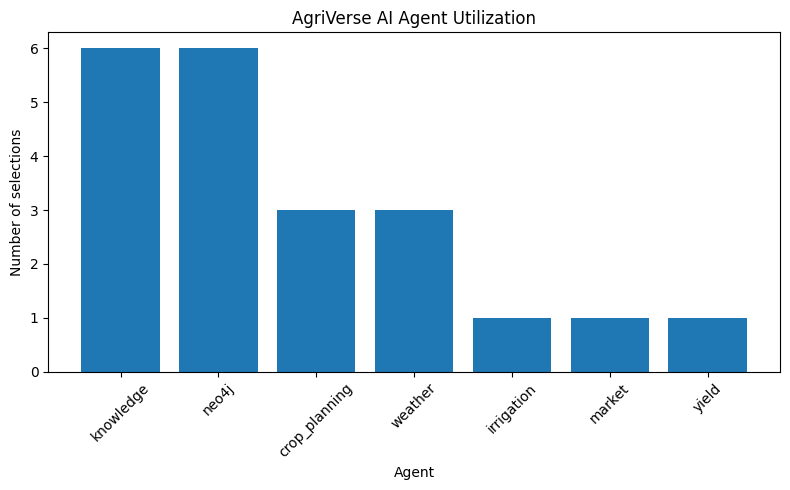

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    agent_usage_df["agent"],
    agent_usage_df["selection_count"]
)

plt.xlabel("Agent")
plt.ylabel("Number of selections")
plt.title("AgriVerse AI Agent Utilization")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

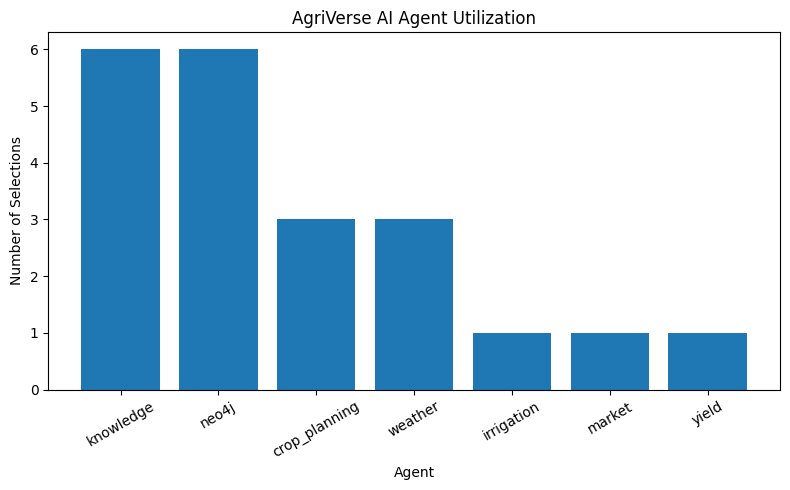

In [ ]:
import matplotlib.pyplot as plt

agents = [
    "knowledge",
    "neo4j",
    "crop_planning",
    "weather",
    "irrigation",
    "market",
    "yield"
]

selection_counts = [6, 6, 3, 3, 1, 1, 1]

plt.figure(figsize=(8, 5))

plt.bar(agents, selection_counts)

plt.xlabel("Agent")
plt.ylabel("Number of Selections")
plt.title("AgriVerse AI Agent Utilization")

plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    "fig_agent_utilization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

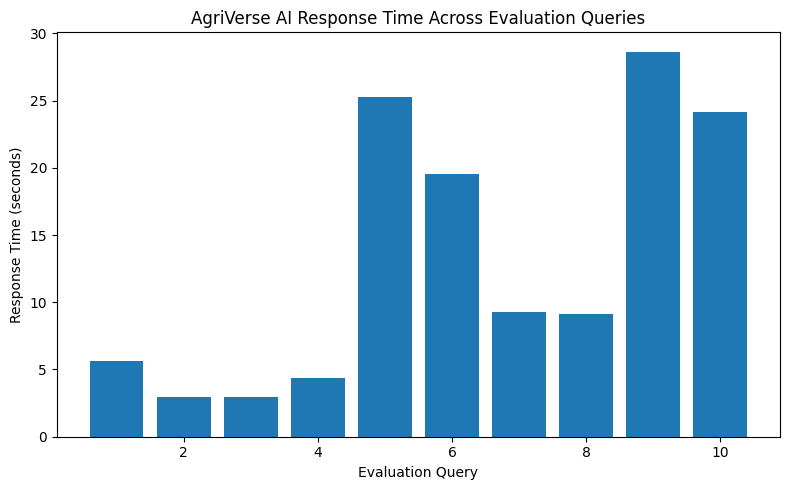

In [ ]:
import matplotlib.pyplot as plt

query_ids = list(range(1, 11))

response_times = [
    5.61,
    2.97,
    2.96,
    4.38,
    25.24,
    19.54,
    9.27,
    9.10,
    28.64,
    24.15
]

plt.figure(figsize=(8, 5))

plt.bar(query_ids, response_times)

plt.xlabel("Evaluation Query")
plt.ylabel("Response Time (seconds)")
plt.title("AgriVerse AI Response Time Across Evaluation Queries")

plt.tight_layout()

plt.savefig(
    "fig_response_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import os

EVAL_DIR = f"{PROJECT_DIR}/evaluation"
os.makedirs(EVAL_DIR, exist_ok=True)

# Save detailed evaluation results
evaluation_df.to_csv(
    f"{EVAL_DIR}/evaluation_results.csv",
    index=False
)

# Save agent utilization
agent_usage_df.to_csv(
    f"{EVAL_DIR}/agent_utilization.csv",
    index=False
)

# Save summary metrics
summary_df = pd.DataFrame({
    "metric": [
        "Total test queries",
        "Successful queries",
        "Success rate (%)",
        "Average response time (s)",
        "Median response time (s)",
        "Minimum response time (s)",
        "Maximum response time (s)"
    ],
    "value": [
        total_tests,
        successful_tests,
        (successful_tests / total_tests) * 100,
        average_time,
        median_time,
        minimum_time,
        maximum_time
    ]
})

summary_df.to_csv(
    f"{EVAL_DIR}/evaluation_summary.csv",
    index=False
)

print("Evaluation results saved successfully!")

print("\nFiles created:")
print(f"- {EVAL_DIR}/evaluation_results.csv")
print(f"- {EVAL_DIR}/agent_utilization.csv")
print(f"- {EVAL_DIR}/evaluation_summary.csv")

Evaluation results saved successfully!

Files created:
- /content/drive/MyDrive/ai_engineer_3_project/evaluation/evaluation_results.csv
- /content/drive/MyDrive/ai_engineer_3_project/evaluation/agent_utilization.csv
- /content/drive/MyDrive/ai_engineer_3_project/evaluation/evaluation_summary.csv


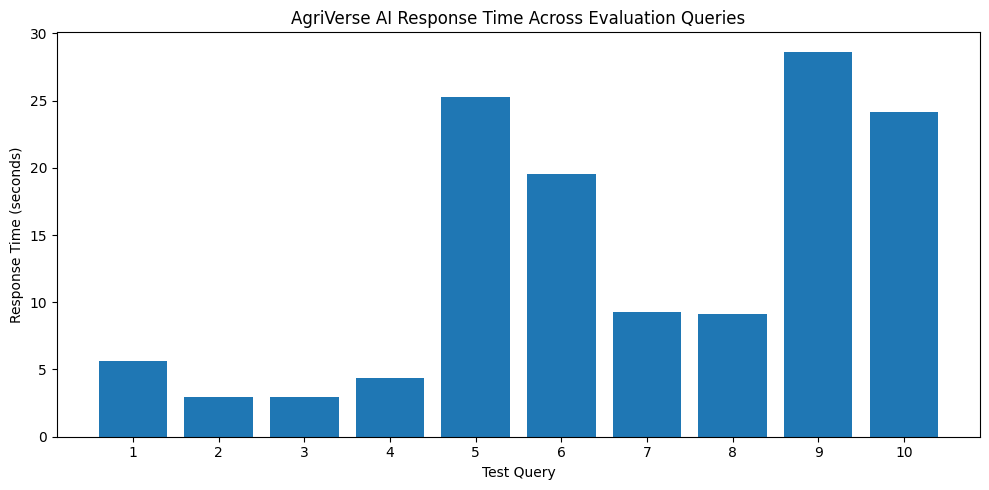

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    evaluation_df["id"],
    evaluation_df["response_time_sec"]
)

plt.xlabel("Test Query")
plt.ylabel("Response Time (seconds)")
plt.title("AgriVerse AI Response Time Across Evaluation Queries")

plt.xticks(evaluation_df["id"])
plt.tight_layout()
plt.show()